### PRAPEMROSESAN DATA

### Import Library dan Konfigurasi

In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install Sastrawi

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Import library
import os
import re
import json
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from tqdm import tqdm

# Pengaturan
PATH_GABUNGAN = "data/gojek_reviews_clean.csv"
PATH_KAMUS    = "data/colloquial-indonesian-lexicon.csv"
PATH_CACHE    = "data/stem_cache.json"       # simpan hasil stemming per kata
KECUALIKAN_NEGASI = True   # True = kata negasi (tidak, bukan, dst.) TIDAK dibuang saat stopword removal

os.makedirs("data", exist_ok=True)
print("Folder kerja:", os.getcwd())   # harus berakhir di ...\skripsi_gojek

Folder kerja: c:\Users\LENOVO\OneDrive\Documents\Skripsi\Implementasi_gojek\implementasiSkripsi


In [5]:
# 2. Unduh data pendukung NLTK
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [6]:
# 3. Baca data
df = pd.read_csv(PATH_GABUNGAN, dtype={"review_id": str})
df["review"] = df["review"].astype(str)

print("Jumlah ulasan:", len(df))      
df[["review_id", "review", "source"]].head(10)

Jumlah ulasan: 55414


,review_id,review,source
0,gp_a1c1ed7a-0ab8-4756-9256-a8caf0ff844a,sangat membantu untuk beraktifitas.,Google Play Store
1,gp_5baf7979-ab7d-489d-ab71-0b0b1e41c019,Tapjek 👍,Google Play Store
2,gp_a50155cc-d000-4c7b-b85d-8d558cd95531,trimakasi sudah mengantarkan aku ke tempat tuj...,Google Play Store
3,gp_9a1026f3-7662-40e7-819b-b92dd34538da,nyaman dan aman selamat sampai tujuan,Google Play Store
4,gp_417cf4d5-af97-42da-bb9e-c290b1fd4b5c,mantap,Google Play Store
5,as_13084398690,Nice work,App Store
6,as_13084429082,Super-App,App Store
7,gp_1d1341b0-e006-4474-8f37-66304b080dc6,Bagus Bgt,Google Play Store
8,gp_5f52cf99-b1f4-4df8-b263-fbe073518c5d,Please.... voucher nya susah banget dapet....,Google Play Store
9,gp_1d0f3831-ad77-41ef-ae13-cf58a2cb6728,mantap,Google Play Store


### 1. CLEANING TEXT

In [7]:
# 1. Bersihkan teks
def data_cleaning(teks):
    teks = re.sub(r"http\S+|www\.\S+", " ", teks, flags=re.IGNORECASE)   # 1) URL
    teks = re.sub(
        "[" 
        "\U0001F300-\U0001FAFF"   # emoji & simbol
        "\U00002600-\U000027BF"   # simbol lain (hati, centang, dll.)
        "\U0001F000-\U0001F2FF"
        "\U0000FE00-\U0000FE0F"   # variation selector
        "\U0000200D"              # zero-width joiner
        "]+", " ", teks)                                                  # 2) emoji
    teks = re.sub(r"\d+", " ", teks)                                      # 3) angka
    teks = re.sub(r"[^A-Za-z\s]", " ", teks)                              # 4) tanda baca & sisa karakter non-huruf
    teks = re.sub(r"\s+", " ", teks).strip()                              # 5) rapikan spasi berlebih
    return teks

# 2. Uji dulu pada satu contoh sebelum dijalankan ke semua data
print(data_cleaning("Mantap banget!!! 😍😍 cek https://gojek.com 5x bintang, drivernya ramah-ramah :)"))

Mantap banget cek x bintang drivernya ramah ramah


In [8]:
# 3. Sample berisi ulasan yang mengandung URL, angka, emoji, tanda baca dari data ulasan sebelum cleaning
sample = df[df["review"].str.contains("http|www|[0-9]|😍|!")]

# 4. Bandingkan sebelum dan sesudah cleaning
for teks in sample["review"].head():
    print("Sebelum :", teks)
    print("Sesudah :", data_cleaning(teks))
    print("-" * 50)

Sebelum : kenapa sih fitur chat sama driver susah bgt. selalu centang 1. bisa bikin aplikasi gak?
Sesudah : kenapa sih fitur chat sama driver susah bgt selalu centang bisa bikin aplikasi gak
--------------------------------------------------
Sebelum : Selalu andalan!
Sesudah : Selalu andalan
--------------------------------------------------
Sebelum : Semoga pengusaha, investor, jajaran manajemen dan mitra driver GOJEK ada dalam keberkahan dunia akhirat, terimakasih selalu jadi kontributor nyata dari rakyat untuk negara Indonesia. 生意兴隆 GO-JEK!
Sesudah : Semoga pengusaha investor jajaran manajemen dan mitra driver GOJEK ada dalam keberkahan dunia akhirat terimakasih selalu jadi kontributor nyata dari rakyat untuk negara Indonesia GO JEK
--------------------------------------------------
Sebelum : makin parah pelayanan untuk go food nya tiap hari order selalu gda driver mau ambil padahal udah 5 tahun pake gojek tapi ke sini ke sini nya makin parah sampai akhirnya pesan pake apk lain sump

In [9]:
# 5. Simpan Hasil Data Cleaning
df["review_clean"] = df["review"].apply(data_cleaning)
df[["review", "review_clean"]].sample(5, random_state=1)

,review,review_clean
7115,"APLIKASI CACAT, DOWNLOAD DOANG BESAR, MASUK AP...",APLIKASI CACAT DOWNLOAD DOANG BESAR MASUK APLI...
26523,pesan makanan lama padahal jarak dekat.! hampi...,pesan makanan lama padahal jarak dekat hampir ...
55237,SUSAH BANGET DAPET DRIVER WAKTU PESEN GOFOOD,SUSAH BANGET DAPET DRIVER WAKTU PESEN GOFOOD
22930,"Recently, app Gojek ini banyak masalahnya. Sus...",Recently app Gojek ini banyak masalahnya Susah...
7469,Baguslah poko e,Baguslah poko e


In [10]:
# 6. Simpan hasil ke file CSV
def simpan(df, nama_file):
    df.to_csv(f"data/{nama_file}", index=False, encoding="utf-8-sig")
    print("Tersimpan: data/" + nama_file)

simpan(df, "praproses_1_cleaning.csv")

Tersimpan: data/praproses_1_cleaning.csv


### 2. CASE FOLDING

In [11]:
# 1. Ubah semua teks menjadi huruf kecil (lowercase)
df["review_fold"] = df["review_clean"].str.lower()
df[["review_clean", "review_fold"]].sample(5, random_state=1)

,review_clean,review_fold
7115,APLIKASI CACAT DOWNLOAD DOANG BESAR MASUK APLI...,aplikasi cacat download doang besar masuk apli...
26523,pesan makanan lama padahal jarak dekat hampir ...,pesan makanan lama padahal jarak dekat hampir ...
55237,SUSAH BANGET DAPET DRIVER WAKTU PESEN GOFOOD,susah banget dapet driver waktu pesen gofood
22930,Recently app Gojek ini banyak masalahnya Susah...,recently app gojek ini banyak masalahnya susah...
7469,Baguslah poko e,baguslah poko e


In [12]:
# 2. Simpan hasil ke file CSV
simpan(df, "praproses_2_casefolding.csv")

Tersimpan: data/praproses_2_casefolding.csv


### 3. Normalization

In [13]:
# 1. Baca kamus Clloquial Indonesian Lexicon
kamus_df = pd.read_csv(PATH_KAMUS, sep=";")
print(kamus_df.columns.tolist())
kamus_df.head(10)

['slang', 'formal', 'In-dictionary', 'context', 'category1', 'category2', 'category3']


,slang,formal,In-dictionary,context,category1,category2,category3
0,woww,wow,1,wow,elongasi,0,0
1,aminn,amin,1,Selamat ulang tahun kakak tulus semoga panjang...,elongasi,0,0
2,met,selamat,1,Met hari netaas kak!? Wish you all the best @t...,abreviasi,0,0
3,netaas,menetas,1,Met hari netaas kak!? Wish you all the best @t...,afiksasi,elongasi,0
4,keberpa,keberapa,0,Birthday yg keberpa kak?,abreviasi,0,0
5,eeeehhhh,eh,1,Eh ada @ghessawarsana . Eeeehhhh,elongasi,0,0
6,kata2nyaaa,kata-katanya,0,Kata2nyaaa ?,reduplikasi,elongasi,0
7,hallo,halo,1,Hallo kakak tulus,elongasi,0,0
8,kaka,kakak,1,Ngefans banget sama kaka? sukses selalu ka? @t...,zeroisasi,0,0
9,ka,kak,1,Ngefans banget sama kaka? sukses selalu ka? @t...,zeroisasi,0,0


In [14]:
# 2. Membentuk & membersihkan kamus Normalisasi
KOLOM_SLANG, KOLOM_FORMAL = "slang", "formal"

kamus_df = kamus_df[[KOLOM_SLANG, KOLOM_FORMAL]].dropna()
kamus_df[KOLOM_SLANG]  = kamus_df[KOLOM_SLANG].str.lower().str.strip()
kamus_df[KOLOM_FORMAL] = kamus_df[KOLOM_FORMAL].str.lower().str.strip()
kamus_df = kamus_df[kamus_df[KOLOM_SLANG] != kamus_df[KOLOM_FORMAL]]   # buang pasangan yang sama
kamus_df = kamus_df.drop_duplicates(subset=KOLOM_SLANG, keep="first")  # satu slang = satu padanan

kamus_norm = dict(zip(kamus_df[KOLOM_SLANG], kamus_df[KOLOM_FORMAL]))
print("Jumlah entri kamus:", len(kamus_norm))

Jumlah entri kamus: 4338


In [15]:
# 3. Normalisasi teks ulasan
# Daftar kata dasar baku dari Sastrawi (hanya untuk mengecek apakah sebuah kata valid)
KATA_BAKU = set(StemmerFactory().get_words())
print("Jumlah kata dasar baku:", len(KATA_BAKU))

# Koreksi MANUAL (prioritas tertinggi). Satu dict, tiap kunci hanya satu kali.
KOREKSI_MANUAL = {
    # --- typo dan variasi penulisan ---
    "trimakasih": "terima kasih", "trimakasi": "terima kasih", "terimakasih": "terima kasih", "god": "bagus", "n": "dan", "rbu": "ribu", "kaya": "kayak",
    "tks": "terima kasih", "makasih": "terima kasih", "thankyou": "terima  kasih", "ttpi": "tetapi", "tapi": "tetapi", "mnit": "menit", "ijo": "hijau",
    "mantab": "mantap", "mantabb": "mantap", "mantaf": "mantap", "mantul": "mantap", "nipu": "tipu", "bofoh": "jelek", "tranportasi": "transportasi",
    "mntap": "mantap", "mantull": "mantap", "jos": "mantap", "joss": "mantap", "mantaps": "mantap", "jidanya": "jidatnya", "gratis": "free", "syeqalee": "sekali",
    "beraktifitas": "beraktivitas", "aktifitas": "aktivitas", "tarip": "tarif", "okeh": "oke", "okey": "oke", "dpat": "dapat", "syekali": "sekali",
    "lemoot": "lemot", "nomer": "nomor", "rejeki": "rezeki", "alesan": "alasan", "alesannya": "alasannya", "promonyaa": "promo", "promonya": "promo",
    "vocer": "voucher", "indak": "tidak", "samsek": "sama sekali", "tlong": "tolong","anjg": "anjing", "jrak": "jarak", "perbyk": "perbanyak",
    "oendaraan": "kendaraan", "eror": "error", "expres": "express","sngat": "sangat", "mangkin":"makin", "woii": "woi", "datengnya": "datangnya",
    "dtng": "datang", "psen": "pesan", "dulu": "dahulu", "prmberitahuan": "pemberitahuan", "okk": "oke", "bis": "bisa", "pantesan": "pantas",
    "shope": "shopee", "shoppe": "shopee", "nelpon": "telepon", "telpon": "telepon", "nelvon": "telepon", "phone": "telepon", "tlpn": "telepon",
    
    # --- singkatan dan istilah ---
    "cancle": "cancel", "cansel": "cancel", "batalin": "cancel","canclenya": "cancelnya", "batal": "cancel", 
    "jlk": "jelek", "jls": "jelas", "gjls": "tidak jelas", "gasuka": "tidak suka", "kgk": "tidak", "enggak": "tidak", "kga": "tidak",
    "dc": "debt collector", "ongkir": "ongkos kirim", "ongkirnya": "ongkos kirim", "dkt": "dekat",
    "rekomen": "rekomendasi", "recomended": "rekomendasi", "recommended": "rekomendasi",
    "resto": "restoran", "restonya": "restoran",
    "ok": "oke", "okay": "oke", "hp": "ponsel", "telp": "telepon", "telfon": "telepon",
    "byr": "bayar", "tf": "transfer", "jm": "jam", "tbtb": "tiba tiba",
    "wa": "whatsapp", "instal": "install", "uninstal": "uninstall", "gd": "tidak ada", "gada": "tidak ada",
    "plis": "tolong", "pliss": "tolong", "pls": "tolong", "please": "tolong",
    "gopaypinjam": "gopay pinjam", "mls": "malas", "tb": "tiba", "disc": "diskon", "discon": "diskon", "discont": "diskon", "disconnya": "diskon",

    # --- kata sentimen Inggris -> Indonesia (InSet hanya mengenal bahasa Indonesia) ---
    "good": "bagus", "goodd": "bagus", "nice": "bagus", "great": "bagus", "goodjob": "bagus",
    "excellent": "bagus", "gacor": "bagus", "awesome": "hebat", 
    "best": "terbaik", "love": "suka", "like": "suka", "happy": "senang",
    "easy": "mudah", "easier": "mudah", "simple": "mudah",
    "fast": "cepat", "gercep": "cepat", "satset": "cepat",
    "helpful": "membantu", "helpfull": "membantu", "amazing": "hebat",
    "useful": "berguna", "usefull": "berguna", "useless": "tidak berguna",
    "friendly": "ramah", "better": "lebih baik", "well": "baik",
    "bad": "jelek", "worst": "terburuk", "slow": "lambat", "scam": "penipuan",
    "worth": "layak", "sorry": "maaf", "suspend": "blokir", "stuck": "macet",
    "support": "dukungan", "thanks": "terima kasih", "thank": "terima kasih",
    "thx": "terima kasih",

    # --- kata bahasa Inggris umum -> Indonesia ---
    "very": "sangat", "somuch": "sangat", "food": "makanan", "close": "tutup", "fair": "adil", "its": "ini",
    "job": "pekerjaan", "jobs": "pekerjaan", "work": "berfungsi", "works": "berfungsi", "but": "tetapi",
    "booking": "pemesanan", "bookingnya": "pemesanan", "booked": "dipesan", "book": "pesan", "urgent": "penting",
    "order": "pesan", "ngorder": "pesan", "ordering": "pesan", "ngeorder": "pesan", "help": "membantu",
    "pengemudi": "driver", "drever": "driver", "service": "layanan", "servicenya": "layanan",

    # --- slang sentimen ---
    "asik": "asyik", "ribet": "sulit", "lag": "lambat", "ngelag": "lambat", "ngeleg": "lambat",
    "delay": "lambat", "komplen": "komplain", "complain": "komplain",
    "ngeluh": "mengeluh", "belagu": "sombong", "mager": "malas", "rame": "ramai",
    "ngotak": "masuk akal", "ngaco": "tidak masuk akal", "gaje": "tidak masuk akal",
    "gara": "karena", "bapuk": "jelek", "cool": "keren",

    # --- slang kata kerja ---
    "dibatalin": "dicancel", 
    "mesen": "pesan", "ngambil": "mengambil", "benerin": "perbaiki",
    "dibenerin": "diperbaiki", "nganter": "mengantar", "nolak": "menolak",
    "nemu": "menemukan", "maksa": "memaksa", "mikir": "berpikir",
    "balikin": "kembalikan", "ditungguin": "ditunggu",
    "gadapet": "tidak dapat", "dpet": "dapat", "dapetnya": "dapat",
    "nunggunya": "menunggu", "muter": "berputar", "nyangkut": "tersangkut",
    "nyantol": "tersangkut", "nyasar": "tersesat", "laper": "lapar",
    "ujan": "hujan", "ngebug": "error", 
    "ngebatalin": "ngecancel", "naikin": "naikkan", "turunin": "turunkan",
    "matiin": "matikan", "hubungin": "hubungi", "nyuruh": "menyuruh",
    "pinjem": "pinjam", "knapa": "kenapa", "gegara": "karena", "kelaperan": "kelaparan",
    "mageran": "malas", "markotop": "mantap", "zonk": "kecewa",

    # --- penyeragaman istilah ---
    "supir": "driver", "supirnya": "driver", "drivers": "driver", "drivernya": "driver", 
    "drivernyaa": "driver", "driverr": "driver", "driverny": "driver", "ontime": "tepat waktu",
    "app": "aplikasi", "apps": "aplikasi", "apl": "aplikasi", "apk": "aplikasi",
    "system": "sistem", "application": "aplikasi", "aplication": "aplikasi",
    "apknya": "aplikasi", "appnya": "aplikasi", "aplikasinya": "aplikasi",
    "gojeg": "gojek", "jek": "gojek", "hape":"ponsel", "gocarr": "gocar",
    "ojolnya": "ojol", "responnya": "respon", "services": "layanan",
    "loadingnya": "loading", "argonya": "argo", "call": "call",
    "lu": "kamu", "lo": "kamu", "gue": "saya", "gw": "saya", "gua": "saya", "tak": "saya",
    "ku": "aku", "i": "saya", "you": "kamu", "my": "saya", "me": "saya",

    # --- customer: satukan ke "customer" dan "customer_service" ---
    "customer": "customer", "customers": "customer", "customernya": "customer",
    "cust": "customer", "custnya": "customer",
    "coutumer": "customer", "costumer": "customer", "custumer": "customer",
    "kustomer": "customer", "kostumer": "customer",
    "pelanggan": "customer", "pelanggannya": "customer",
    "konsumen": "customer", "konsumennya": "customer",
    "cs": "customer_service", "csnya": "customer_service",
    "customerservice": "customer_service",

    # --- negasi: satukan ke "tidak" ---
    "enggak": "tidak", "kagak": "tidak", "tiada": "tidak ada",
    "bukannya": "bukan", "bukanya": "bukan",
    "gaakan": "tidak akan", "gaperlu": "tidak perlu", "gaguna": "tidak berguna",
    "gamasuk": "tidak masuk", "gapapa": "tidak apa apa", "gadapat": "tidak dapat",
    "gajelass": "tidak jelas", "ganiat": "tidak niat",
}

# Frasa yang terpisah/menyatu salah (diproses SEBELUM koreksi per kata)
KOREKSI_FRASA = {
    r"\bgo\s+jek\b": "gojek",
    r"\bgo\s+pay\b": "gopay",
    r"\bgrab\s+food\b": "grabfood",
    r"\bgo\s+ride\b": "goride",
    r"\bgo\s+car\b": "gocar",
    r"\bgo\s+shop\b": "goshop",
    r"\bgo\s+send\b": "gosend",
    r"\bgo\s+mart\b": "gomart",
    r"\bgo\s+clean\b": "goclean",
    r"\bgo\s+bluebird\b": "gobluebird",
    r"\bgo\s+comfort\b": "gocomfort",
    r"\bgo\s+express\b": "goexpress",
    r"\bgo\s+hemat\b": "gohemat",
    r"\bgopay\s+later\b": "gopaylater",
    r"\bgo\s+box\b": "gobox",
    r"\bgo\s+transit\b": "gotransit",
    r"\bgo\s+gopinjam\b": "gopinjam",
    r"\btop\s+up\b": "topup",
    r"\bpop\s+up\b": "popup",
    r"\bpick\s+up\b": "pickup",
    r"\be\s+wallet\b": "ewallet",
    r"\be\s+money\b": "emoney",
    r"\bgood\s+job\b": "bagus",
    r"\bon\s+time\b": "tepat waktu",
    r"\bgara\s+gara\b": "karena",
    r"\bgo\s+clean\b": "goclean",
    r"\bthe\s+best\b": "terbaik",
    r"\bthe\s+bestlah\b": "terbaik",
    r"\bthe\s+besst\b": "terbaik",
    r"\bsok?\s+far\s+sok?\s+(?:bagus|good|gud|god)\b": "sejauh ini bagus",
    r"\bsok?\s+far\s+sok?\b": "sejauh ini",                      # "sok far sok aman" -> "sejauh ini aman"
    r"\bfar\s+sok?\s+(?:bagus|good|gud|god)\b": "sejauh ini bagus",
    r"\bfar\s+sok?\b": "sejauh ini",                             # "far sok" saja
    r"\bsok?\s+far\b": "sejauh ini",                             # "sok far" / "so far" saja
        r"\bcall?[\s\-_.]*(?:center|centre|senter|sentre)(?:nya)?\b": "call center",
    r"\bsho+p+e+[\s\-_.]*food\b": "shopeefood",
    r"\bgo+[\s\-_.]*fo+d(?:nya)?\b": "gofood",
    r"\b(?:customer|cust|costumer|custumer|coutumer)[\s\-]+(?:service|services|servis|care)\b": "customer_service",
    r"\b(?:layanan|pelayanan|service|servis)\s+(?:pelanggan|customer|konsumen)\b": "customer_service",
    # 1) "no" + objek bernomor -> nomor (harus lebih dulu)
    r"\bno\.?\s+(?=(?:hp|ponsel|telp|telpon|telepon|tlp|tlpn|wa|whatsapp|rekening|rek|"
    r"pesanan|order|plat|pol|polisi|akun|kartu|ktp|va|id|resi|penerima|darurat|baru|"
    r"yang|saya|driver)\b)": "nomor ",
    # 2) "no" + kata lain -> tidak
    r"\bno\s+(?=[a-z])": "tidak ",
}

PEMETAAN_AKHIR = {
    "enggak": "tidak", "nggak": "tidak", "gak": "tidak", "ga": "tidak",
    "gk": "tidak", "kagak": "tidak", "ngga": "tidak", "engga": "tidak",
    "dicancel": "cancel", "ngecancel": "cancel", "cancelnya": "cancel",
}

# Fungsi normalisasi teks ulasan
def kurangi_huruf_berulang(teks):
    # 3 huruf sama atau lebih menjadi 2 (jelekkkk -> jelekk)
    return re.sub(r"(.)\1{2,}", r"\1\1", teks)

def normalisasi(teks):
    teks = kurangi_huruf_berulang(teks)
    for pola, ganti in KOREKSI_FRASA.items():
        teks = re.sub(pola, ganti, teks)
    hasil = []
    for kata in teks.split():
        if kata in KOREKSI_MANUAL:                 # 1) koreksi manual
            kata = KOREKSI_MANUAL[kata]
        elif kata in kamus_norm:                   # 2) kamus Colloquial
            kata = kamus_norm[kata]
            kata = KOREKSI_MANUAL.get(kata, kata)  # 3) cek ulang hasil kamus ke koreksi manual
        elif kata not in KATA_BAKU:                # 4) huruf dobel -> tunggal jika jadi kata baku
            satu = re.sub(r"(.)\1+", r"\1", kata)
            if satu in KATA_BAKU:
                kata = satu
        hasil.append(kata)
    hasil = [PEMETAAN_AKHIR.get(k, k) for k in " ".join(hasil).split()]  # sekali saja, di luar loop
    return " ".join(hasil)

df["review_norm"] = df["review_fold"].apply(normalisasi)
df[["review_fold", "review_norm"]].sample(8, random_state=1)

Jumlah kata dasar baku: 29933


,review_fold,review_norm
7115,aplikasi cacat download doang besar masuk apli...,aplikasi cacat download doang besar masuk apli...
26523,pesan makanan lama padahal jarak dekat hampir ...,pesan makanan lama padahal jarak dekat hampir ...
55237,susah banget dapet driver waktu pesen gofood,susah banget dapat driver waktu pesan gofood
22930,recently app gojek ini banyak masalahnya susah...,recently aplikasi gojek ini banyak masalahnya ...
7469,baguslah poko e,baguslah pokok e
45342,terbaik dan mudah digunakan,terbaik dan mudah digunakan
31523,sangat membantu,sangat membantu
25580,layanan memuaskan,layanan memuaskan


In [16]:
# 4. Mengecek kamus koreksi manual-kamus
print("Kunci multi-kata:", [k for k in KOREKSI_MANUAL if " " in k])
print("Rantai koreksi:", [(k, v) for k, v in KOREKSI_MANUAL.items()
                          if v in KOREKSI_MANUAL and KOREKSI_MANUAL[v] != v])
print("Jumlah entri KOREKSI_MANUAL:", len(KOREKSI_MANUAL))

Kunci multi-kata: []
Rantai koreksi: []
Jumlah entri KOREKSI_MANUAL: 303


In [17]:
# 5a. Cari kandidat kata tidak baku
stemmer_cek = StemmerFactory().create_stemmer()

In [18]:
# 5b. Cari kandidat kata tidak baku
from collections import Counter

# Kata sah yang sengaja dibiarkan (tambah sesuai kebutuhan)
KATA_SAH = {
    # layanan dan merek Gojek / kompetitor / mitra
    "gojek", "gopay", "gofood", "gocar", "goride", "gosend", "gomart", "gopinjam", "gotransit", "gopaylater",
    "paylater", "goto", "grab", "maxim", "shopee", "tokopedia", "nadiem", "xl", "krl", "extra", "bike", "gocats",
    "pinjol", "sameday", "express", "comfort", "pickup", "pick", "double", "instant", "goshop", "grabfood", 
    "gofood", "shopeefood", "ruby", "goplus",

    # istilah aplikasi dan teknologi
    "driver", "pelanggan", "promo", "chat", "fitur", "voucher", "order", "update", "upgrade", "rider",
    "error", "bug", "login", "email", "online", "offline", "saldo", "restoran", "merchant", "pt",
    "maps", "mapsnya", "qris", "otp", "server", "wifi", "gps", "internet", "ios", "iphone", "ui",
    "install", "uninstall", "download", "loading", "notif", "admin", "user", "game", "spam", "qr",
    "whatsapp", "google", "template", "review", "rating", "refund", "topup", "cash", "coin", "coins",
    "payment", "delivery", "transport", "ride", "ojol", "aplikator", "argo", "plat", "ktp", "rp",
    "tips", "fee", "discount", "ponsel", "respon", "merespon", "direspon", "jakarta", "refresh", "seller",
    "pemberitahuan", "seringkali", "segitu", "karyawan", "ai", "gmail", "history", "playstore", "sms",
    "reward", "device", "load", "daily", "google play", "play store", "acc", "cancel", "dicancel", "ngecancel",
    "store", "tiktok", "ojk", "setting", "tracking", "chat", "dichat", "telepon", "token",
    "customer", "customer_service", "rs", "ig", "down", "otw", "force", "off",
    
     # istilah bahasa
     "attitude", "gonta", "dzolim",
}

SW_CEK = set(StopWordRemoverFactory().get_stop_words()) | {"nya", "ya", "di", "ke"}

frek = Counter(k for teks in df["review_norm"] for k in teks.split())

kandidat = []
for kata, n in frek.most_common(5000):
    if n < 20:
        break
    if kata in KATA_BAKU or kata in SW_CEK or kata in KATA_SAH:
        continue
    if kata.endswith("nya") and kata[:-3] in (KATA_BAKU | KATA_SAH):   # drivernya, appnya, dst.
        continue
    if stemmer_cek.stem(kata) in KATA_BAKU:   # berimbuhan, dasarnya baku
        continue
    kandidat.append((kata, n))

print("Kandidat kata tidak baku:", len(kandidat))
# cetak 4 kolom agar ringkas
baris = [f"{k}({n})" for k, n in kandidat[:200]]
for i in range(0, len(baris), 4):
    print("   ".join(f"{b:24s}" for b in baris[i:i+4]))

total = sum(frek.values())
sisa = sum(n for k, n in kandidat)
print(f"\nKemunculan kandidat typo/slang: {sisa/total:.1%} dari semua token")

Kandidat kata tidak baku: 98
mulu(518)                  tuh(335)                   eh(324)                    an(306)                 
pak(162)                   go(145)                    nge(136)                   b(110)                  
free(99)                   a(90)                      drive(85)                  up(84)                  
hadeh(78)                  se(78)                     ah(77)                     woi(73)                 
full(68)                   e(67)                      hadehh(60)                 is(59)                  
car(58)                    si(58)                     wkwk(57)                   all(56)                 
and(56)                    time(55)                   on(54)                     ber(53)                 
bye(51)                    call(48)                   by(47)                     the(46)                 
woy(40)                    debt(40)                   wow(39)                    t(38)                   
collector(38)    

In [19]:
# 5c. Cek ulasan yang mengandung kata tertentu (untuk melihat konteksnya)
import textwrap

def cek_konteks(kata, n=6, seed=1):
    """Tampilkan n ulasan asli yang mengandung kata (pada hasil normalisasi)."""
    cocok = df[df["review_norm"].str.contains(rf"\b{re.escape(kata)}\b", regex=True)]
    print(f"=== '{kata}' | {len(cocok)} ulasan ===")
    for _, r in cocok.sample(min(n, len(cocok)), random_state=seed).iterrows():
        # potong teks di sekitar kata supaya mudah dibaca
        t = r["review_norm"]
        i = re.search(rf"\b{re.escape(kata)}\b", t).start()
        potong = t[max(0, i - 50): i + 50]
        print("  ...", potong, "...")
    print()

# Kata satu huruf dan kata ambigu
for k in ["cal center","call center", "customer_service far", "sejauh ini"]:
    cek_konteks(k, n=5)

=== 'cal center' | 0 ulasan ===

=== 'call center' | 28 ulasan ===
  ... call center busuk tidak bisa dikontak ...
  ... i pakai orang lain respon tidak solutif tidak ada call center ...
  ... a bantuan customer_service yang memadai tidak ada call center dm instagram saya dibalas beberapa har ...
  ... olong perbaiki sistem customer_service mengadakan call center jam untuk berbicara dengan manusia buk ...
  ... spon customer_service kurang baik tidak ada nomor call center yang bisa di hubungi respon tidak baik ...

=== 'customer_service far' | 0 ulasan ===

=== 'sejauh ini' | 241 ulasan ===
  ... sejauh ini tidak ada kendala apapun dan selalu ter ...
  ... sampai sejauh ini sih masih oke aplikasi dan driver nya b ...
  ... bagus sih sejauh ini ...
  ... sejauh ini sikap driver gocarnya baik dan ramah te ...
  ... belum pernah kecewa sejauh ini ...



In [20]:
# 6. Simpan hasil ke file CSV
simpan(df, "praproses_3_normalization.csv")

Tersimpan: data/praproses_3_normalization.csv


### 4. Tokenizing

In [21]:
# 1. Memecah kalimat menjadi token/kata
df["tokens"] = df["review_norm"].apply(word_tokenize)
df[["review_norm", "tokens"]].sample(10, random_state=1)

,review_norm,tokens
7115,aplikasi cacat download doang besar masuk apli...,"[aplikasi, cacat, download, doang, besar, masu..."
26523,pesan makanan lama padahal jarak dekat hampir ...,"[pesan, makanan, lama, padahal, jarak, dekat, ..."
55237,susah banget dapat driver waktu pesan gofood,"[susah, banget, dapat, driver, waktu, pesan, g..."
22930,recently aplikasi gojek ini banyak masalahnya ...,"[recently, aplikasi, gojek, ini, banyak, masal..."
7469,baguslah pokok e,"[baguslah, pokok, e]"
45342,terbaik dan mudah digunakan,"[terbaik, dan, mudah, digunakan]"
31523,sangat membantu,"[sangat, membantu]"
25580,layanan memuaskan,"[layanan, memuaskan]"
48005,bagus banget coy kalo pesan makanan tuh cepat ...,"[bagus, banget, coy, kalo, pesan, makanan, tuh..."
6408,cukup bagus,"[cukup, bagus]"


In [22]:
# 2. Simpan hasil ke file CSV
df["review_token"] = df["tokens"].apply(lambda t: " ".join(t))
simpan(df.drop(columns=["tokens"]), "praproses_4_tokenizing.csv")

Tersimpan: data/praproses_4_tokenizing.csv


### 5. Stopword Removal

In [23]:
# 1a. cek negasi di data
from collections import Counter

frek_token = Counter(t for tokens in df["tokens"] for t in tokens)
stopwords_sastrawi = set(StopWordRemoverFactory().get_stop_words())

# Kandidat negasi: bentuk baku + variasi slang/singkatan
kandidat_negasi = [
    "tidak", "bukan", "belum", "jangan", "kurang", "tak", "tanpa", "tiada",
    "nggak", "enggak", "gak", "ga", "gk", "ngga", "nggk", "tdk", "blm", "jgn", "kagak",
    "gabisa", "gaada", "gada", "gaje", "ngak", "engga", "enggan", "mustahil",
]

print(f"{'kata':12s} {'frekuensi':>10s}  stopword Sastrawi?")
for k in kandidat_negasi:
    n = frek_token.get(k, 0)
    if n > 0:
        print(f"{k:12s} {n:10d}  {'YA' if k in stopwords_sastrawi else 'tidak'}")

kata          frekuensi  stopword Sastrawi?
tidak             22536  YA
bukan               816  tidak
belum               960  YA
jangan             1295  tidak
kurang              637  tidak
tanpa               494  YA
gada                  4  tidak
enggan                4  tidak


In [24]:
# 1b. cek negasi lain di data
import re

pola = re.compile(r"^(ga|gak|ngga|nggak|enggak|engga|tdk|tak|blm|jgn|non|tanpa|tidak|belum|bukan)")
ketemu = [(k, n) for k, n in frek_token.items() if pola.match(k) and n >= 10]
ketemu = sorted(ketemu, key=lambda x: -x[1])[:40]
for k, n in ketemu:
    print(f"{k:15s} {n}")

tidak           22536
belum           960
bukan           816
tanpa           494
ganti           449
gampang         235
gagal           205
gangguan        136
game            127
takut           99
non             49
ganggu          46
gambar          38
gang            34
gas             33
gaji            27
gacoan          22
galak           21
nongol          19
gandos          19
taksi           17
gaya            17
gan             16
nongkrong       15
gara-gara       14
galeri          14
gantung         12
nonaktifkan     11
take            11
takutnya        11
ganguan         10
games           10


In [25]:
# 2. Daftar Stopword
stopwords = set(StopWordRemoverFactory().get_stop_words())
print("Jumlah stopword Sastrawi:", len(stopwords))

# Negasi dari hasil cek data
NEGASI = {"tidak", "bukan", "belum", "jangan", "kurang", "tanpa", "enggan", "non"}
print("Negasi yang ada di stopword Sastrawi:", sorted(NEGASI & stopwords))

# Tambahan stopword: slang tanpa makna dan huruf tunggal 
STOPWORD_TAMBAHAN = {
    "tuh", "eh", "ah", "an", "aku", "ku", "ane", "kamu", "kita", "kalian", "mereka", "dia", "si", "nge", "se", "ber", "tb", "woi", "woy", 
    "lol", "wkwk", "wkwkwk", "hadeh", "hadehh", "nah", "dulu", "wow", "dear", "et", "noh",
    "n", "t", "b", "e", "a", "l", "an", "p", "ve", "nya", "ya", "sih", "ih", "lho", 
    "hadeh", "hadehh", "hehehe", "hehe", "hhe", "hahaha", "haha", "banget", "sangat", "sama", "jadi", "buat", "kali", "kalau", "kalo",
    "padahal", "malah", "aw", "a", "the", "yasyasyas", "coy", "deh", "apa", "lah",
}

stopwords = (stopwords | STOPWORD_TAMBAHAN)
if KECUALIKAN_NEGASI:
    stopwords = stopwords - NEGASI
print("Jumlah stopword akhir:", len(stopwords))
print("Negasi masih terbuang? ->", sorted(NEGASI & stopwords))   # harus []

Jumlah stopword Sastrawi: 123
Negasi yang ada di stopword Sastrawi: ['belum', 'tanpa', 'tidak']
Jumlah stopword akhir: 181
Negasi masih terbuang? -> []


In [26]:
# 3. Stopword Removal
def hapus_stopword(tokens):
    return [t for t in tokens if t not in stopwords]

df["tokens_nostop"] = df["tokens"].apply(hapus_stopword)
df["review_nostop"] = df["tokens_nostop"].apply(lambda t: " ".join(t))
df[["review_token", "review_nostop"]].sample(10, random_state=1)

,review_token,review_nostop
7115,aplikasi cacat download doang besar masuk apli...,aplikasi cacat download doang besar masuk apli...
26523,pesan makanan lama padahal jarak dekat hampir ...,pesan makanan lama jarak dekat hampir tidak sa...
55237,susah banget dapat driver waktu pesan gofood,susah driver waktu pesan gofood
22930,recently aplikasi gojek ini banyak masalahnya ...,recently aplikasi gojek banyak masalahnya susa...
7469,baguslah pokok e,baguslah pokok
45342,terbaik dan mudah digunakan,terbaik mudah digunakan
31523,sangat membantu,membantu
25580,layanan memuaskan,layanan memuaskan
48005,bagus banget coy kalo pesan makanan tuh cepat ...,bagus pesan makanan cepat suka
6408,cukup bagus,cukup bagus


In [27]:
# 4. Cek hasil stopword removal
panjang_sebelum = df["tokens"].apply(len).sum()
panjang_sesudah = df["tokens_nostop"].apply(len).sum()
print(f"Token: {panjang_sebelum:,} -> {panjang_sesudah:,} ({1 - panjang_sesudah/panjang_sebelum:.1%} dibuang)")

# negasi harus masih ada
frek_ns = Counter(t for tokens in df["tokens_nostop"] for t in tokens)
for k in ["tidak", "belum", "tanpa", "bukan", "jangan", "kurang"]:
    print(f"{k:8s} {frek_ns.get(k, 0)}")

# kata teratas setelah stopword, untuk memeriksa apakah masih ada sisa kata tanpa makna
print(frek_ns.most_common(40))

Token: 625,701 -> 429,890 (31.3% dibuang)
tidak    22536
belum    960
tanpa    494
bukan    816
jangan   1295
kurang   637
[('tidak', 22536), ('driver', 17056), ('gojek', 9556), ('aplikasi', 9479), ('bagus', 7201), ('pesan', 5467), ('lama', 4607), ('mau', 4511), ('mantap', 4449), ('cancel', 4275), ('membantu', 4067), ('oke', 3775), ('menunggu', 3767), ('pakai', 3602), ('kasih', 3094), ('gofood', 2965), ('banyak', 2921), ('lebih', 2865), ('jam', 2854), ('cepat', 2711), ('susah', 2642), ('selalu', 2468), ('baik', 2293), ('terima', 2186), ('makanan', 2173), ('terus', 2136), ('customer', 2084), ('makin', 2070), ('sekarang', 2063), ('sekali', 2046), ('jauh', 1861), ('waktu', 1775), ('promo', 1701), ('sering', 1607), ('tiba', 1594), ('mahal', 1537), ('jelas', 1519), ('gopay', 1465), ('suka', 1463), ('ramah', 1457)]


In [28]:
# 5. Simpan hasil ke file CSV
simpan(df.drop(columns=["tokens", "tokens_nostop"]), "praproses_5_stopword.csv")

Tersimpan: data/praproses_5_stopword.csv


### 6. Stemming

In [29]:

# stemming kosakata unik dengan cache agar efisien
stemmer = StemmerFactory().create_stemmer()

# 1. kumpulkan kata unik
kosakata = set(t for tokens in df["tokens_nostop"] for t in tokens)
print("Jumlah kata unik:", len(kosakata))

# 2. muat cache jika ada (kalau notebook pernah dijalankan sebelumnya)
if os.path.exists(PATH_CACHE):
    with open(PATH_CACHE, encoding="utf-8") as f:
        cache_stem = json.load(f)
else:
    cache_stem = {}

# 3. stem hanya kata yang belum ada di cache
belum = [k for k in kosakata if k not in cache_stem]
print("Kata yang perlu di-stem:", len(belum))

for kata in tqdm(belum):
    cache_stem[kata] = stemmer.stem(kata)

with open(PATH_CACHE, "w", encoding="utf-8") as f:
    json.dump(cache_stem, f, ensure_ascii=False)

Jumlah kata unik: 20108
Kata yang perlu di-stem: 0


0it [00:00, ?it/s]


In [30]:
# 4. lakukan stemming pada token review menggunakan cache
def stem_tokens(tokens):
    return [cache_stem.get(t, t) for t in tokens]

df["tokens_stem"] = df["tokens_nostop"].apply(stem_tokens)
df["review_stem"] = df["tokens_stem"].apply(lambda t: " ".join(t))

# contoh: kata "membantu" -> "bantu"
print(cache_stem.get("membantu"))
df[["review_nostop", "review_stem"]].sample(10, random_state=1)

bantu


,review_nostop,review_stem
7115,aplikasi cacat download doang besar masuk apli...,aplikasi cacat download doang besar masuk apli...
26523,pesan makanan lama jarak dekat hampir tidak sa...,pesan makan lama jarak dekat hampir tidak sahu...
55237,susah driver waktu pesan gofood,susah driver waktu pesan gofood
22930,recently aplikasi gojek banyak masalahnya susa...,recently aplikasi gojek banyak masalah susah p...
7469,baguslah pokok,bagus pokok
45342,terbaik mudah digunakan,baik mudah guna
31523,membantu,bantu
25580,layanan memuaskan,layan muas
48005,bagus pesan makanan cepat suka,bagus pesan makan cepat suka
6408,cukup bagus,cukup bagus


In [31]:
# 5. Cek hasil dan buang ulasan kosong
kosong = df["review_stem"].str.strip() == ""
print("Ulasan kosong setelah prapemrosesan:", kosong.sum())
print("Per sumber:\n", df[kosong]["source"].value_counts())

df_final = df[~kosong].copy().reset_index(drop=True)
print("Jumlah ulasan akhir:", len(df_final))

Ulasan kosong setelah prapemrosesan: 626
Per sumber:
 source
Google Play Store    477
App Store            149
Name: count, dtype: int64
Jumlah ulasan akhir: 54788


In [ ]:
# 6. Cek semua nilai kosong
s = df_final["review_stem"]

print("NaN               :", s.isna().sum())
print("String kosong     :", (s.fillna("x").astype(str).str.strip() == "").sum())
print("Berisi '[]'/'nan' :", s.astype(str).str.strip().isin(["[]", "nan", "None"]).sum())
print("Tipe data         :", s.map(type).value_counts().to_dict())

# Lihat contoh baris yang bermasalah
bermasalah = df_final[s.isna() | s.astype(str).str.strip().isin(["", "[]", "nan", "None"])]
print(len(bermasalah))
print(bermasalah[["review_id", "review", "review_nostop", "review_stem"]].head(10).to_string())

NaN               : 0
String kosong     : 0
Berisi '[]'/'nan' : 0
Tipe data         : {<class 'str'>: 54788}
0
Empty DataFrame
Columns: [review_id, review, review_nostop, review_stem]
Index: []


In [33]:
# Simpan versi lengkap (semua sub-tahap) + versi ringkas untuk tahap berikutnya
kolom_simpan = ["review_id", "review", "review_clean", "review_fold", "review_norm",
                "review_token", "review_nostop", "review_stem", "rating", "date", "source"]
simpan(df_final[kolom_simpan], "gojek_praproses.csv")

Tersimpan: data/gojek_praproses.csv


### PEMODELAN TOPIK LATENT DIRICHLET ALLOCATION (LDA)

### Import, path, dan konfigurasi

In [34]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
%pip install matplotlib gensim statsmodels tqdm pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
# 1. Cek kernel dan paket Python 3.12
import sys
print(sys.version)
print(sys.executable)   

import gensim, matplotlib, statsmodels, pandas, numpy, scipy
print("gensim      :", gensim.__version__)
print("matplotlib  :", matplotlib.__version__)
print("statsmodels :", statsmodels.__version__)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
c:\Users\LENOVO\OneDrive\Documents\Skripsi\Implementasi_gojek\implementasiSkripsi\.venv312\Scripts\python.exe
gensim      : 4.4.0
matplotlib  : 3.11.2
statsmodels : 0.15.0


In [37]:
# 2. Import dan Konfigurasi
import os, pickle
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from gensim.corpora import Dictionary
from gensim.models import Phrases, LdaMulticore, CoherenceModel
from gensim.models.phrases import Phraser

BASE_DIR  = Path.cwd()
DATA_DIR  = BASE_DIR / "data"
MODEL_DIR = BASE_DIR / "model"
HASIL_DIR = BASE_DIR / "hasil"
for d in (MODEL_DIR, HASIL_DIR):
    d.mkdir(exist_ok=True)

# ---------- Pengaturan ----------
KOLOM_TEKS        = "review_stem"
RENTANG_K         = range(2, 16)
SEED              = 42
WORKERS           = 7
PASSES            = 10
COHERENCE_PROC    = 1
BIGRAM_MIN_COUNT  = 20
BIGRAM_THRESHOLD  = 10
FILTER_EXTREMES   = True
NO_BELOW, NO_ABOVE = 20, 0.5
STOPWORD_LDA      = set()

print("Folder kerja:", BASE_DIR)
print("File ada    :", (DATA_DIR / "gojek_praproses.csv").exists())

df = pd.read_csv(DATA_DIR / "gojek_praproses.csv", sep=None, engine="python",
                 encoding="utf-8-sig", dtype={"review_id": str})
print(df.shape)
print(df.columns.tolist())

Folder kerja: c:\Users\LENOVO\OneDrive\Documents\Skripsi\Implementasi_gojek\implementasiSkripsi
File ada    : True
(54788, 11)
['review_id', 'review', 'review_clean', 'review_fold', 'review_norm', 'review_token', 'review_nostop', 'review_stem', 'rating', 'date', 'source']


### 1. Pembentukan Bigram

In [38]:
# 1. Muat data dan siapkan token
# Baca ulang: keep_default_na=False agar ulasan bertuliskan "nan"/"none" tidak dianggap kosong
df = pd.read_csv(DATA_DIR / "gojek_praproses.csv", sep=None, engine="python",
                 encoding="utf-8-sig", dtype={"review_id": str}, keep_default_na=False)

# Buang kolom "Unnamed" (kolom kosong sisa Excel)
df = df.loc[:, ~df.columns.str.startswith("Unnamed")].copy()

# Pastikan kolom teks bertipe string, lalu rapikan indeks
df[KOLOM_TEKS] = df[KOLOM_TEKS].astype(str)
df = df.reset_index(drop=True)

print(df.shape)                                   # harus (54789, 11)
print(df.columns.tolist())
print("Ulasan kosong      :", (df[KOLOM_TEKS].str.strip() == "").sum())
print("review_id unik     :", df["review_id"].is_unique)
print(df["source"].value_counts())

(54788, 11)
['review_id', 'review', 'review_clean', 'review_fold', 'review_norm', 'review_token', 'review_nostop', 'review_stem', 'rating', 'date', 'source']
Ulasan kosong      : 0
review_id unik     : True
source
Google Play Store    43680
App Store            11108
Name: count, dtype: int64


In [39]:
# 2. Pembentukan Bigram
# Pecah teks hasil stemming menjadi token
tokens = [[t for t in teks.split() if t not in STOPWORD_LDA] for teks in df[KOLOM_TEKS]]

# Deteksi dan terapkan bigram
phrases = Phrases(tokens, min_count=BIGRAM_MIN_COUNT, threshold=BIGRAM_THRESHOLD, delimiter="_")
bigram  = Phraser(phrases)
docs    = [bigram[t] for t in tokens]

# Periksa bigram yang terbentuk
frek_bigram = Counter(k for d in docs for k in d if "_" in k)
print("Jumlah jenis bigram:", len(frek_bigram))
print(frek_bigram.most_common())

Jumlah jenis bigram: 143
[('terima_kasih', 1933), ('customer_service', 1000), ('ongkos_kirim', 841), ('mau_ambil', 683), ('banyak_promo', 571), ('tiba_tiba', 533), ('tepat_waktu', 525), ('masuk_akal', 347), ('makin_kesini', 297), ('suruh_tunggu', 263), ('kasih_bintang', 255), ('kayak_begini', 230), ('hampir_jam', 218), ('beli_makan', 212), ('titik_jemput', 205), ('gopay_pinjam', 204), ('ambil_order', 162), ('buang_waktu', 153), ('aman_nyaman', 140), ('luar_biasa', 134), ('tengah_jam', 133), ('benar_benar', 129), ('goride_hemat', 126), ('sukses_selalu', 121), ('metode_bayar', 121), ('saldo_gopay', 116), ('buru_buru', 113), ('jarak_dekat', 112), ('tanggung_jawab', 106), ('sat_set', 105), ('pilih_pilih', 104), ('akhir_akhir', 104), ('kirim_barang', 104), ('buang_buang', 103), ('tiap_hari', 97), ('double_pesan', 97), ('minta_ampun', 96), ('ramah_sopan', 87), ('titik_lokasi', 82), ('orang_lapar', 80), ('ujung_ujung', 78), ('restoran_tutup', 77), ('pernah_telat', 75), ('niat_kerja', 74), ('p

### 2. Pembentukan Corpus

In [40]:
# Dictionary: beri ID pada setiap kata unik
dictionary = Dictionary(docs)
print("Kata unik sebelum filter:", len(dictionary))

# Buang kata terlalu jarang (<20 ulasan) dan terlalu umum (>50% ulasan)
if FILTER_EXTREMES:
    dictionary.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE)
    print("Kata unik setelah filter:", len(dictionary))

# Corpus: setiap ulasan menjadi pasangan (id_kata, frekuensi)
corpus_all = [dictionary.doc2bow(d) for d in docs]

# Ulasan yang kosong setelah filter tidak bisa dimodelkan
idx_valid  = [i for i, b in enumerate(corpus_all) if len(b) > 0]
corpus     = [corpus_all[i] for i in idx_valid]
docs_valid = [docs[i] for i in idx_valid]
print(f"Ulasan dipakai LDA: {len(corpus):,} dari {len(df):,}")

# Simpan agar tidak perlu mengulang
dictionary.save(str(MODEL_DIR / "lda_dictionary.dict"))
with open(MODEL_DIR / "idx_valid.pkl", "wb") as f:
    pickle.dump(idx_valid, f)

Kata unik sebelum filter: 15627
Kata unik setelah filter: 1294
Ulasan dipakai LDA: 53,650 dari 54,788


### 3. Pemodelan LDA

In [41]:
# 1. Uji alternatif jumlah topik (k)
hasil_koherensi = []
for k in RENTANG_K:
    path_model = MODEL_DIR / f"lda_k{k}.model"
    if path_model.exists():
        lda = LdaMulticore.load(str(path_model))          # pakai model yang sudah ada
    else:
        lda = LdaMulticore(corpus=corpus, id2word=dictionary, num_topics=k,
                           workers=WORKERS, passes=PASSES, random_state=SEED,
                           chunksize=2000, eval_every=None)  # eval_every=None mempercepat
        lda.save(str(path_model))

    cm = CoherenceModel(model=lda, texts=docs_valid, dictionary=dictionary,
                        coherence="c_v", processes=COHERENCE_PROC)
    skor = cm.get_coherence()
    hasil_koherensi.append({"k": k, "coherence_cv": skor})
    print(f"k={k:2d}  C_v={skor:.4f}")

df_koh = pd.DataFrame(hasil_koherensi)
df_koh.to_csv(HASIL_DIR / "lda_coherence.csv", index=False)
df_koh

k= 2  C_v=0.5697
k= 3  C_v=0.5355
k= 4  C_v=0.5882
k= 5  C_v=0.5701
k= 6  C_v=0.6146
k= 7  C_v=0.5866
k= 8  C_v=0.5921
k= 9  C_v=0.6182
k=10  C_v=0.5863
k=11  C_v=0.5891
k=12  C_v=0.5890
k=13  C_v=0.5917
k=14  C_v=0.5999
k=15  C_v=0.6140


,k,coherence_cv
0,2,0.569743
1,3,0.535533
2,4,0.588230
3,5,0.570099
4,6,0.614551
5,7,0.586598
6,8,0.592116
7,9,0.618243
8,10,0.586299
9,11,0.589061


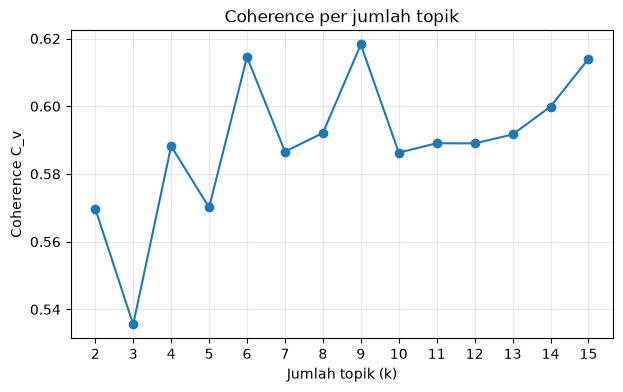

In [42]:
# 2. Grafik coherence per k
plt.figure(figsize=(7, 4))
plt.plot(df_koh["k"], df_koh["coherence_cv"], marker="o")
plt.xlabel("Jumlah topik (k)"); plt.ylabel("Coherence C_v")
plt.title("Coherence per jumlah topik")
plt.xticks(list(df_koh["k"])); plt.grid(alpha=.3)
plt.savefig(HASIL_DIR / "lda_coherence.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# # 3. Menampilkan isi masing-masing topik
# for k in df_koh.sort_values("coherence_cv", ascending=False)["k"].head(3):
#     lda_k = LdaMulticore.load(str(MODEL_DIR / f"lda_k{k}.model"))
#     print(f"\n===== k = {k} =====")
#     for t in range(k):
#         print(f"T{t}:", ", ".join(w for w, _ in lda_k.show_topic(t, topn=10)))

# 3. Menampilkan isi masing-masing topik untuk semua k (2-15)
for k in RENTANG_K:
    path_model = MODEL_DIR / f"lda_k{k}.model"
    if not path_model.exists():
        print(f"\nModel k={k} belum ada, dilewati")
        continue
    lda_k = LdaMulticore.load(str(path_model))
    cv = df_koh.loc[df_koh["k"] == k, "coherence_cv"].values[0]
    print(f"\n===== k = {k} | C_v = {cv:.4f} =====")
    for t in range(k):
        print(f"T{t}:", ", ".join(w for w, _ in lda_k.show_topic(t, topn=10)))


===== k = 2 | C_v = 0.5697 =====
T0: tidak, driver, aplikasi, pesan, gojek, lama, cancel, tunggu, mau, pakai
T1: bagus, mantap, gojek, baik, oke, bantu, aplikasi, driver, layan, cepat

===== k = 3 | C_v = 0.5355 =====
T0: tidak, driver, pesan, aplikasi, cancel, gojek, lama, tunggu, mau, jam
T1: bagus, baik, oke, aplikasi, gojek, layan, terima_kasih, driver, banyak, keren
T2: bantu, mantap, driver, gojek, cepat, mudah, aplikasi, makin, mahal, jauh

===== k = 4 | C_v = 0.5882 =====
T0: tidak, aplikasi, gojek, pakai, mau, bayar, gopay, masuk, hari, guna
T1: bagus, bantu, baik, gojek, aplikasi, terima_kasih, layan, keren, banyak, sekali
T2: mantap, driver, cepat, gojek, makin, mahal, mudah, harga, lebih, pakai
T3: driver, tidak, pesan, cancel, lama, tunggu, oke, jam, gofood, makan

===== k = 5 | C_v = 0.5701 =====
T0: tidak, aplikasi, gojek, pakai, mau, gopay, masuk, bayar, jelas, guna
T1: gojek, baik, driver, terima_kasih, tidak, aplikasi, banyak, customer, layan, suka
T2: mantap, cepat,

In [44]:
# 4. Tetapkan K final (default = coherence tertinggi; ganti manual jika kata dominan k lain lebih sesuai)
K_FINAL = int(df_koh.loc[df_koh["coherence_cv"].idxmax(), "k"])
print("K_FINAL =", K_FINAL)
lda = LdaMulticore.load(str(MODEL_DIR / f"lda_k{K_FINAL}.model"))

K_FINAL = 9


### 4. Ekstraksi Topik (Langkah Selanjutnya Menunngu Annotator)

In [ ]:
ANNOTATOR = ["A1", "A2", "A3"]

# Distribusi topik setiap ulasan -> matriks (n_ulasan x K)
theta = np.zeros((len(corpus), K_FINAL))
for i, dist in enumerate(lda.get_document_topics(corpus, minimum_probability=0)):
    for t, p in dist:
        theta[i, t] = p

teks_asli = df["review"].astype(str).values
baris = []
for t in range(K_FINAL):
    kata   = ", ".join(f"{w}({p:.3f})" for w, p in lda.show_topic(t, topn=15))
    top_i  = np.argsort(-theta[:, t])[:5]
    contoh = " || ".join(teks_asli[idx_valid[i]].replace("\n", " ") for i in top_i)

    row = {"topik_id": t, "kata_dominan": kata, "ulasan_representatif": contoh}
    for a in ANNOTATOR:
        row[f"{a}_aspek"] = ""
        row[f"{a}_subaspek"] = ""
    baris.append(row)

df_anotasi = pd.DataFrame(baris)
df_anotasi.to_csv(HASIL_DIR / "lda_anotasi_aspek.csv", index=False, encoding="utf-8-sig")
df_anotasi[["topik_id", "kata_dominan"]]

,topik_id,kata_dominan
0,0,"tidak(0.078), aplikasi(0.029), gojek(0.025), m..."
1,1,"gojek(0.065), banyak(0.042), driver(0.035), ti..."
2,2,"driver(0.083), makin(0.041), susah(0.035), jau..."
3,3,"bantu(0.189), baik(0.176), tidak(0.037), custo..."
4,4,"sekali(0.108), selalu(0.048), pesan(0.039), hu..."
5,5,"tidak(0.107), aplikasi(0.051), pakai(0.031), m..."
6,6,"tidak(0.104), driver(0.087), pesan(0.045), can..."
7,7,"bagus(0.278), mantap(0.175), oke(0.151), aplik..."
8,8,"terima_kasih(0.061), gojek(0.059), driver(0.05..."


### 5. Validasi label aspek

In [ ]:
# 1. Baca Data
from collections import Counter
from statsmodels.stats.inter_rater import fleiss_kappa, aggregate_raters

ann = pd.read_csv(HASIL_DIR / "lda_hasil_anotasi_aspek.csv", sep=None, engine="python",
                  encoding="utf-8-sig", keep_default_na=False)

# Rapikan label (spasi di ujung)
for c in ["A1", "A2", "A3"]:
    ann[c] = ann[c].astype(str).str.strip()

# Pemeriksaan
print("Kolom        :", ann.columns.tolist())
print("Jumlah topik :", len(ann), "| K_FINAL =", K_FINAL)
print("topik_id     :", ann["topik_id"].tolist())
print("Label kosong :", (ann[["A1", "A2", "A3"]] == "").sum().to_dict())
print("Label unik   :", sorted(set(ann[["A1", "A2", "A3"]].values.ravel())))
ann[["topik_id", "A1", "A2", "A3"]]

Kolom        : ['topik_id', 'kata_dominan', 'ulasan_representatif', 'A1', 'A2', 'A3', 'A1_subaspek', 'A2_subaspek', 'A3_subaspek']
Jumlah topik : 9 | K_FINAL = 9
topik_id     : [0, 1, 2, 3, 4, 5, 6, 7, 8]
Label kosong : {'A1': 0, 'A2': 0, 'A3': 0}
Label unik   : ['IT service reliability', 'responsiveness', 'security', 'suitability', 'tangibility', 'usability']


,topik_id,A1,A2,A3
0,0,security,security,security
1,1,tangibility,usability,usability
2,2,IT service reliability,IT service reliability,suitability
3,3,responsiveness,responsiveness,responsiveness
4,4,responsiveness,responsiveness,responsiveness
5,5,IT service reliability,IT service reliability,IT service reliability
6,6,responsiveness,responsiveness,responsiveness
7,7,usability,usability,usability
8,8,usability,usability,usability


In [ ]:
# 2. Menghitung fleiss' kappa
assert (ann[["A1", "A2", "A3"]] != "").all().all(), "Masih ada sel A1-A3 yang kosong"

kode, kategori = pd.factorize(ann[["A1", "A2", "A3"]].values.ravel())
tabel, _ = aggregate_raters(kode.reshape(-1, 3))
kappa = fleiss_kappa(tabel, method="fleiss")
print(f"Fleiss' kappa = {kappa:.3f} | topik = {len(ann)} | kategori dipakai = {len(kategori)}")

Fleiss' kappa = 0.803 | topik = 9 | kategori dipakai = 6


In [ ]:
# 3. Majority voting
from collections import Counter

# >=2 annotator sama -> label akhir
def majority(row):
    label, n = Counter([row["A1"], row["A2"], row["A3"]]).most_common(1)[0]
    return label

ann["label_majority"] = ann.apply(majority, axis=1)

# Pengecekan: pastikan tidak ada topik yang ketiga annotator-nya beda semua
n_sama = ann.apply(lambda r: Counter([r["A1"], r["A2"], r["A3"]]).most_common(1)[0][1], axis=1)
assert (n_sama >= 2).all(), "Ada topik yang ketiga annotator-nya beda semua"

print(ann[["topik_id", "A1", "A2", "A3", "label_majority"]])
ann.to_csv(HASIL_DIR / "lda_validasi_aspek.csv", index=False, encoding="utf-8-sig")

   topik_id                      A1                      A2                      A3          label_majority
0         0                security                security                security                security
1         1             tangibility               usability               usability               usability
2         2  IT service reliability  IT service reliability             suitability  IT service reliability
3         3          responsiveness          responsiveness          responsiveness          responsiveness
4         4          responsiveness          responsiveness          responsiveness          responsiveness
5         5  IT service reliability  IT service reliability  IT service reliability  IT service reliability
6         6          responsiveness          responsiveness          responsiveness          responsiveness
7         7               usability               usability               usability               usability
8         8               us

### 6. Pelabelan Aspek pada Seluruh Ulasan

In [ ]:
# 1. pelabelan ulasan valid 
topic_to_aspect = dict(zip(ann["topik_id"], ann["label_majority"]))
aspects = sorted(set(topic_to_aspect.values()))

# Pengecekan keselarasan (harus lolos semua)
assert len(docs) == len(df), f"docs={len(docs)} != df={len(df)}"
assert lda.num_topics == K_FINAL == len(ann)
assert theta.shape == (len(corpus), K_FINAL)
assert len(idx_valid) == len(corpus)

# Skor per aspek = jumlah probabilitas topik dalam aspek itu
skor = pd.DataFrame({
    a: theta[:, [t for t, lab in topic_to_aspect.items() if lab == a]].sum(axis=1)
    for a in aspects
})

df_aspek = df.iloc[idx_valid].copy()
df_aspek["idx_asli"]      = idx_valid
df_aspek["aspek"]         = skor.idxmax(axis=1).values
df_aspek["aspek_prob"]    = skor.max(axis=1).values
df_aspek["topik_dominan"] = theta.argmax(axis=1)
df_aspek = df_aspek.reset_index(drop=True)

print(len(df_aspek), "ulasan berlabel aspek")
print(df_aspek["aspek"].value_counts())

53650 ulasan berlabel aspek
aspek
usability                 24879
responsiveness            15268
IT service reliability    10605
security                   2898
Name: count, dtype: int64


In [ ]:
# 2. pelabelan ulasan jarang/umum yang terbuang (beri label"tidak teridentifikasi") 
df_tak = df.drop(df.index[idx_valid]).copy()
df_tak["idx_asli"]      = df_tak.index
df_tak["aspek"]         = "tidak teridentifikasi"
df_tak["aspek_prob"]    = np.nan
df_tak["topik_dominan"] = np.nan

df_final = (pd.concat([df_aspek, df_tak], ignore_index=True)
              .sort_values("idx_asli").reset_index(drop=True))

assert len(df_final) == len(df), "Jumlah baris tidak sama dengan df"
assert df_final["review_id"].is_unique
print(len(df_tak), "ulasan tidak teridentifikasi")
print(df_final["aspek"].value_counts())

df_final.to_csv(HASIL_DIR / "lda_ulasan_beraspek.csv", index=False, encoding="utf-8-sig")

1138 ulasan tidak teridentifikasi
aspek
usability                 24879
responsiveness            15268
IT service reliability    10605
security                   2898
tidak teridentifikasi      1138
Name: count, dtype: int64


In [ ]:
# 3. Cek keselarasan data awal (df) vs hasil pelabelan (df_final) 
print("Shape awal / final :", df.shape, "/", df_final.shape)
print("Kolom awal         :", df.columns.tolist())
print("Kolom baru         :", [c for c in df_final.columns if c not in df.columns])

# a. Jumlah baris & review_id
assert len(df_final) == len(df), "Jumlah baris berbeda"
assert df_final["review_id"].is_unique, "review_id tidak unik di df_final"
assert set(df_final["review_id"]) == set(df["review_id"]), "Himpunan review_id berbeda"
print("\nUlasan kosong      :", (df_final[KOLOM_TEKS].str.strip() == "").sum())
print("review_id unik     :", df_final["review_id"].is_unique)

# b. Isi kolom asli tidak berubah (cocokkan per review_id)
kolom_asli = df.columns.tolist()
a = df.set_index("review_id")[kolom_asli[1:]].sort_index()
b = df_final.set_index("review_id")[kolom_asli[1:]].sort_index()
print("Isi kolom asli sama:", a.equals(b))

# c. Distribusi source: awal vs final
cmp_src = pd.DataFrame({
    "awal":  df["source"].value_counts(),
    "final": df_final["source"].value_counts(),
})
cmp_src["selisih"] = cmp_src["final"] - cmp_src["awal"]
print("\nsource")
print(cmp_src)

# d. Rincian label aspek
n_valid = len(idx_valid)
n_tak   = (df_final["aspek"] == "tidak teridentifikasi").sum()
print("\nBerlabel aspek      :", len(df_final) - n_tak, "(harus =", n_valid, ")")
print("Tidak teridentifikasi:", n_tak, "(harus =", len(df) - n_valid, ")")
assert (len(df_final) - n_tak) == n_valid
assert n_tak == len(df) - n_valid
print("Aspek kosong (NaN)  :", df_final["aspek"].isna().sum())

print("\naspek")
print(df_final["aspek"].value_counts())

# e. Rincian aspek per source (memastikan tidak ada source yang hilang)
print("\naspek x source")
print(pd.crosstab(df_final["aspek"], df_final["source"], margins=True))

# f. Urutan baris sejajar dengan df awal
assert (df_final["review_id"].values == df["review_id"].values).all(), "Urutan baris berbeda"
assert (df_final["idx_asli"].values == np.arange(len(df))).all(), "idx_asli tidak berurutan"
print("\nSemua pengecekan lolos")

Shape awal / final : (54788, 11) / (54788, 15)
Kolom awal         : ['review_id', 'review', 'review_clean', 'review_fold', 'review_norm', 'review_token', 'review_nostop', 'review_stem', 'rating', 'date', 'source']
Kolom baru         : ['idx_asli', 'aspek', 'aspek_prob', 'topik_dominan']

Ulasan kosong      : 0
review_id unik     : True
Isi kolom asli sama: True

source
                    awal  final  selisih
source                                  
Google Play Store  43680  43680        0
App Store          11108  11108        0

Berlabel aspek      : 53650 (harus = 53650 )
Tidak teridentifikasi: 1138 (harus = 1138 )
Aspek kosong (NaN)  : 0

aspek
aspek
usability                 24879
responsiveness            15268
IT service reliability    10605
security                   2898
tidak teridentifikasi      1138
Name: count, dtype: int64

aspek x source
source                  App Store  Google Play Store    All
aspek                                                      
IT service reli

### PELABELAN SENTIMEN LEXICON BASED

### 1. Pseudo-Labeling Sentimen

In [46]:
# Persiapan: muat data dan InSet Lexicon
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

KOLOM_SENTIMEN = "review_stem"     # token hasil stemming (sama dengan yang dipakai LDA)
INSET_DIR = DATA_DIR / "inset"

df_sent = pd.read_csv(DATA_DIR / "gojek_praproses.csv", sep=None, engine="python",
                      encoding="utf-8-sig", dtype={"review_id": str}, keep_default_na=False)
df_sent = df_sent.loc[:, ~df_sent.columns.str.startswith("Unnamed")].copy()
df_sent[KOLOM_SENTIMEN] = df_sent[KOLOM_SENTIMEN].astype(str)

# Baca leksikon (kolom: word, weight)
pos = pd.read_csv(INSET_DIR / "positive.tsv", sep="\t", header=0)
neg = pd.read_csv(INSET_DIR / "negative.tsv", sep="\t", header=0)
pos.columns = ["word", "weight"]; neg.columns = ["word", "weight"]
pos["weight"] =  pos["weight"].abs()      # positif -> +1..+5
neg["weight"] = -neg["weight"].abs()      # negatif -> -5..-1
inset = pd.concat([pos, neg], ignore_index=True)
inset["word"] = inset["word"].astype(str).str.lower().str.strip()
inset = inset[~inset["word"].str.contains(" ")]   # hanya kata tunggal (token review tunggal)
print("Kata InSet:", len(inset), "| positif:", len(pos), "| negatif:", len(neg))

# Stem kata leksikon agar cocok dengan token review yang sudah di-stem
stemmer = StemmerFactory().create_stemmer()
cache_stem = {w: stemmer.stem(w) for w in inset["word"].unique()}
inset["stem"] = inset["word"].map(cache_stem)

# Jika beberapa kata punya stem sama, bobotnya dirata-rata
LEX = inset.groupby("stem")["weight"].mean().to_dict()
print("Entri leksikon setelah stemming:", len(LEX))

Kata InSet: 9478 | positif: 3609 | negatif: 6609
Entri leksikon setelah stemming: 5960


In [47]:
# Polarity score = jumlah bobot semua token yang ada di leksikon (Persamaan 2.1)
def polarity_score(teks):
    return sum(LEX.get(t, 0) for t in teks.split())

df_sent["polarity_score"] = df_sent[KOLOM_SENTIMEN].apply(polarity_score)
df_sent["pseudo_label"] = np.select(
    [df_sent["polarity_score"] > 0, df_sent["polarity_score"] < 0],
    ["positif", "negatif"], default="netral")

print(df_sent["pseudo_label"].value_counts())
print((df_sent["pseudo_label"].value_counts(normalize=True) * 100).round(2))

# Simpan semua hasil, lalu buang netral untuk pemodelan
df_sent.to_csv(HASIL_DIR / "gojek_pseudolabel_semua.csv", index=False, encoding="utf-8-sig")
df_model = df_sent[df_sent["pseudo_label"] != "netral"].reset_index(drop=True)
df_model.to_csv(HASIL_DIR / "gojek_pseudolabel_model.csv", index=False, encoding="utf-8-sig")
print("Data untuk pemodelan (tanpa netral):", df_model.shape)

pseudo_label
negatif    25283
positif    23122
netral      6383
Name: count, dtype: int64
pseudo_label
negatif    46.15
positif    42.20
netral     11.65
Name: proportion, dtype: float64
Data untuk pemodelan (tanpa netral): (48405, 13)


### 2. Penentuan Sampel Validasi (stratified random sampling)

In [48]:
import math

# ===== Cochran: n0 = z² · p · q / e²  (Persamaan 2.2) =====
N = len(df_model)     # populasi validasi = ulasan positif + negatif (tanpa netral)
z = 1.96              # tingkat kepercayaan 95%
p = 0.5               # estimasi proporsi
q = 1 - p             # komplemen proporsi
e = 0.05              # margin of error 5%

n0 = (z**2 * p * q) / e**2                   # ukuran sampel awal (Persamaan 2.2)
n  = n0 / (1 + (n0 - 1) / N)                 # koreksi populasi terbatas
n_cochran = math.ceil(n)                     # dibulatkan ke atas

print(f"N (populasi)                : {N:,}")
print(f"n0 (sebelum koreksi)        : {n0:.2f} -> {math.ceil(n0)}")
print(f"n  (setelah koreksi N)      : {n:.2f} -> {n_cochran}")

# Dipakai di code 3: dibuat genap agar terbagi sama rata per kelas (positif/negatif)
N_TOTAL = n_cochran + (n_cochran % 2)
print(f"N_TOTAL untuk sampel validasi: {N_TOTAL} ({N_TOTAL // 2} per kelas)")

N (populasi)                : 48,405
n0 (sebelum koreksi)        : 384.16 -> 385
n  (setelah koreksi N)      : 381.14 -> 382
N_TOTAL untuk sampel validasi: 382 (191 per kelas)


In [49]:
# 2. Membuat sampel validasi
from sklearn.model_selection import train_test_split

# N_TOTAL sudah dihitung di sel Cochran (jumlah genap agar terbagi sama rata per kelas)
N_PER_KELAS = N_TOTAL // 2          # 191 positif + 191 negatif

bagian = []
for label, g in df_model.groupby("pseudo_label"):
    # Dalam tiap label, ambil N_PER_KELAS ulasan dengan proporsi sumber mengikuti populasi label tsb
    # (stratify=source), random_state tetap -> sampel selalu sama saat dijalankan ulang
    n = min(len(g), N_PER_KELAS)
    ambil, _ = train_test_split(g, train_size=n, stratify=g["source"], random_state=SEED)
    bagian.append(ambil)

sampel = (pd.concat(bagian)
            .sample(frac=1, random_state=SEED)      # acak urutan agar annotator tidak menerima blok satu kelas
            .reset_index(drop=True))

# Cek hasil stratifikasi
print("Total sampel:", len(sampel))
assert len(sampel) == N_TOTAL, f"Jumlah sampel ({len(sampel)}) tidak sama dengan N_TOTAL ({N_TOTAL})"
print(pd.crosstab(sampel["pseudo_label"], sampel["source"], margins=True))

# Bandingkan proporsi sumber: populasi vs sampel (per label)
pop = pd.crosstab(df_model["pseudo_label"], df_model["source"], normalize="index").round(3)
smp = pd.crosstab(sampel["pseudo_label"], sampel["source"], normalize="index").round(3)
print("\nProporsi sumber populasi:\n", pop)
print("\nProporsi sumber sampel:\n", smp)

Total sampel: 382
source        App Store  Google Play Store  All
pseudo_label                                   
negatif              40                151  191
positif              36                155  191
All                  76                306  382

Proporsi sumber populasi:
 source        App Store  Google Play Store
pseudo_label                              
negatif           0.210              0.790
positif           0.187              0.813

Proporsi sumber sampel:
 source        App Store  Google Play Store
pseudo_label                              
negatif           0.209              0.791
positif           0.188              0.812


### 3. Anotasi Sentimen

In [ ]:
# sampel 
file_annotator = sampel[["review_id", "review"]].copy()
for a in ["A1", "A2", "A3"]:
    file_annotator[a] = ""
file_annotator.to_csv(HASIL_DIR / "sentimen_anotasi_annotator.csv", index=False, encoding="utf-8-sig")

# File master (untuk peneliti): pseudo-label + source
sampel[["review_id", "review", "pseudo_label", "source"]].to_csv(
    HASIL_DIR / "sentimen_sampel_master.csv", index=False, encoding="utf-8-sig")

### 4. Validasi Label Sentimen

In [ ]:
# 1. Baca data file dan gabung kolom source dari file sentimen_sampel_master ke sentimen_hasil_anotasi_annotator
import numpy as np
import pandas as pd

KOL_ANN = ["A1", "A2", "A3"]

ann = pd.read_csv(HASIL_DIR / "sentimen_hasil_anotasi_annotator.csv", sep=None, engine="python",
                  encoding="utf-8-sig", dtype={"review_id": str}, keep_default_na=False)
master = pd.read_csv(HASIL_DIR / "sentimen_sampel_master.csv", dtype={"review_id": str}, keep_default_na=False)

# Rapikan isian annotator
for a in KOL_ANN:
    ann[a] = ann[a].astype(str).str.strip().str.lower()

# Cek isian: harus persis "positif" / "negatif"
masalah = False
for a in KOL_ANN:
    salah = ann.loc[~ann[a].isin(["positif", "negatif"]), ["review_id", a]]
    if not salah.empty:
        masalah = True
        print(f"{a}: {len(salah)} isian tidak valid/kosong")
        print(salah.head(10).to_string(index=False))

assert not masalah, "Perbaiki isian yang tidak valid dulu (lihat daftar di atas), lalu jalankan ulang sel ini."

# Cek kecocokan review_id dengan file master
print("review_id unik di file annotator:", ann["review_id"].is_unique)
print("review_id sama dengan master    :", set(ann["review_id"]) == set(master["review_id"]))
print("Jumlah baris annotator / master :", len(ann), "/", len(master))

# Matriks angka (negatif = 0, positif = 1) untuk sel berikutnya
peta = {"negatif": 0, "positif": 1}
matriks = ann[KOL_ANN].apply(lambda s: s.map(peta)).to_numpy()

review_id unik di file annotator: True
review_id sama dengan master    : True
Jumlah baris annotator / master : 382 / 382


In [ ]:
# 2. Cek ketidaksepakatan
ann["n_positif"] = (ann[KOL_ANN] == "positif").sum(axis=1)
ann["sepakat_penuh"] = ann["n_positif"].isin([0, 3])

n_total  = len(ann)
n_penuh  = int(ann["sepakat_penuh"].sum())
n_beda   = n_total - n_penuh
print(f"Total ulasan            : {n_total}")
print(f"Sepakat penuh (3 sama)  : {n_penuh} ({n_penuh / n_total:.1%})")
print(f"Tidak sepakat (2 vs 1)  : {n_beda} ({n_beda / n_total:.1%})")

def annotator_berbeda(r):
    mayoritas = "positif" if r["n_positif"] >= 2 else "negatif"
    return ", ".join(a for a in KOL_ANN if r[a] != mayoritas)

tdk = ann.loc[~ann["sepakat_penuh"]].copy()
tdk["annotator_berbeda"] = tdk.apply(annotator_berbeda, axis=1)

print("\nJumlah kali tiap annotator menjadi suara minoritas:")
print(tdk["annotator_berbeda"].str.split(", ").explode().value_counts())

tdk_out = tdk[["review_id", "review"] + KOL_ANN + ["annotator_berbeda"]]
tdk_out.to_csv(HASIL_DIR / "sentimen_tidak_sepakat.csv", index=False, encoding="utf-8-sig")
print(f"\nDaftar ulasan tidak sepakat disimpan: sentimen_tidak_sepakat.csv ({len(tdk_out)} baris)")
tdk_out.head(10)

Total ulasan            : 382
Sepakat penuh (3 sama)  : 374 (97.9%)
Tidak sepakat (2 vs 1)  : 8 (2.1%)

Jumlah kali tiap annotator menjadi suara minoritas:
annotator_berbeda
A2    6
A1    1
A3    1
Name: count, dtype: int64

Daftar ulasan tidak sepakat disimpan: sentimen_tidak_sepakat.csv (8 baris)


,review_id,review,A1,A2,A3,annotator_berbeda
122,gp_3b984610-513b-4144-acad-ca42c052233f,"mantapp, utk harga ny tolong di turunin dikit ...",positif,negatif,positif,A2
129,gp_e4067da6-f893-4d6b-b770-3ef8de2a536f,harga terlalu murah,negatif,positif,negatif,A2
131,as_14200050440,Banyakin promo ya,positif,negatif,positif,A2
204,gp_a313bd53-0959-4641-ba29-de2559d57907,"pelayanan sudah bagus & nyaman, tapi terkadang...",negatif,positif,positif,A1
258,as_13931336089,Banyakin promonya yaaaaa,positif,negatif,positif,A2
261,gp_6aabc2db-3135-48ae-ab54-c30d6df5217c,"selama di perjalanan saya aman, cuman kadang a...",negatif,positif,negatif,A2
312,gp_f5da6ccd-26d0-46f4-abb1-6d70f2e16274,bikin opsi chat sama penjual,negatif,negatif,positif,A3
374,as_14328426283,Banyakin voucher,positif,negatif,positif,A2


In [ ]:
# 3. Menghitung Fleiss' Kappa
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa

tabel, _ = aggregate_raters(matriks)
kappa = fleiss_kappa(tabel, method="fleiss")

def tafsir(k):   # Landis & Koch (1977)
    if k < 0:     return "poor"
    if k <= 0.20: return "slight"
    if k <= 0.40: return "fair"
    if k <= 0.60: return "moderate"
    if k <= 0.80: return "substantial"
    return "almost perfect"

print(f"Fleiss' Kappa = {kappa:.4f}  ({tafsir(kappa)})")
print(f"Persentase kesepakatan penuh = {ann['sepakat_penuh'].mean():.1%}")

Fleiss' Kappa = 0.9719  (almost perfect)
Persentase kesepakatan penuh = 97.9%


In [ ]:
# 4. Majority Voting
ann["label_final"] = np.where(matriks.sum(axis=1) >= 2, "positif", "negatif")

print("Distribusi ground truth:")
print(ann["label_final"].value_counts())
print((ann["label_final"].value_counts(normalize=True) * 100).round(2))

Distribusi ground truth:
label_final
positif    205
negatif    177
Name: count, dtype: int64
label_final
positif    53.66
negatif    46.34
Name: proportion, dtype: float64


In [ ]:
# 5. Evaluasi Label Inset Lexicon
from sklearn.metrics import accuracy_score, classification_report

hasil = ann.merge(master[["review_id", "pseudo_label", "source"]],
                  on="review_id", how="left", validate="one_to_one")
assert hasil["pseudo_label"].notna().all(), "Ada review_id yang tidak cocok dengan file master"

# Keseluruhan
print("Akurasi InSet vs ground truth:", round(accuracy_score(hasil["label_final"], hasil["pseudo_label"]), 4))
print(classification_report(hasil["label_final"], hasil["pseudo_label"], digits=4))
print("Confusion matrix (baris = ground truth, kolom = InSet):")
print(pd.crosstab(hasil["label_final"], hasil["pseudo_label"], margins=True))

# Akurasi per label InSet (precision tiap label) dan estimasi akurasi populasi
hasil["cocok"] = hasil["label_final"] == hasil["pseudo_label"]
akurasi_kelas = hasil.groupby("pseudo_label")["cocok"].mean()
bobot_pop = df_model["pseudo_label"].value_counts(normalize=True)
print("\nAkurasi per label InSet:\n", akurasi_kelas.round(4))
print("Estimasi akurasi populasi (dibobot proporsi kelas populasi):",
      round(float((akurasi_kelas * bobot_pop.reindex(akurasi_kelas.index)).sum()), 4))

# Per sumber
print("\nAkurasi InSet per sumber:")
print(hasil.groupby("source")["cocok"].agg(n="size", akurasi="mean").round(4))

# Simpan ground truth
hasil[["review_id", "review", "source"] + KOL_ANN + ["label_final", "pseudo_label"]].to_csv(
    HASIL_DIR / "sentimen_ground_truth.csv", index=False, encoding="utf-8-sig")
print("\nTersimpan: sentimen_ground_truth.csv")

Akurasi InSet vs ground truth: 0.8586
              precision    recall  f1-score   support

     negatif     0.8220    0.8870    0.8533       177
     positif     0.8953    0.8341    0.8636       205

    accuracy                         0.8586       382
   macro avg     0.8586    0.8606    0.8584       382
weighted avg     0.8613    0.8586    0.8588       382

Confusion matrix (baris = ground truth, kolom = InSet):
pseudo_label  negatif  positif  All
label_final                        
negatif           157       20  177
positif            34      171  205
All               191      191  382

Akurasi per label InSet:
 pseudo_label
negatif    0.8220
positif    0.8953
Name: cocok, dtype: float64
Estimasi akurasi populasi (dibobot proporsi kelas populasi): 0.857

Akurasi InSet per sumber:
                     n  akurasi
source                         
App Store           76   0.8684
Google Play Store  306   0.8562

Tersimpan: sentimen_ground_truth.csv


### GORUND TRUTH DIGUNAKAN UNTUK MENGGANTI LABEL ULASAN SAMPEL VALIDASI INSET LEXICON

In [128]:
# 1. Ganti label InSet dengan ground truth (hanya review_id yang ada di sampel validasi)
import numpy as np
import pandas as pd

df_model = pd.read_csv(HASIL_DIR / "gojek_pseudolabel_model.csv", sep=None, engine="python",
                       encoding="utf-8-sig", dtype={"review_id": str}, keep_default_na=False)
df_model[KOLOM_SENTIMEN] = df_model[KOLOM_SENTIMEN].astype(str)

gt = pd.read_csv(HASIL_DIR / "sentimen_ground_truth.csv", sep=None, engine="python",
                 encoding="utf-8-sig", dtype={"review_id": str}, keep_default_na=False)
assert gt["review_id"].is_unique
gt_map = dict(zip(gt["review_id"], gt["label_final"]))
assert set(gt_map) <= set(df_model["review_id"]), "Ada review_id ground truth yang tidak ada di data model"

# Kolom label = label InSet, lalu ditimpa ground truth untuk review_id yang ada di sampel
df_model["label"] = df_model["pseudo_label"]
is_gt = df_model["review_id"].isin(gt_map)
df_model.loc[is_gt, "label"] = df_model.loc[is_gt, "review_id"].map(gt_map)
df_model["sumber_label"] = np.where(is_gt, "ground_truth", "inset")

# Pengecekan
berubah = (df_model["label"] != df_model["pseudo_label"]).sum()
print("Ulasan memakai ground truth :", int(is_gt.sum()))
print("Label yang berubah          :", int(berubah), f"({berubah / is_gt.sum():.1%} dari sampel)")
print(pd.crosstab(df_model["sumber_label"], df_model["label"], margins=True))

df_model.to_csv(HASIL_DIR / "gojek_label_sentimen_final.csv", index=False, encoding="utf-8-sig")

Ulasan memakai ground truth : 382
Label yang berubah          : 54 (14.1% dari sampel)
label         negatif  positif    All
sumber_label                         
ground_truth      177      205    382
inset           25092    22931  48023
All             25269    23136  48405


### HASIL & VISUALISASI PEMODELAN TOPIK LDA

In [ ]:
# 1. Ringkasan topik -> aspek (hasil pemodelan LDA) 
# Baca label aspek hasil validasi ke variabel BARU (jangan pakai `ann` agar tidak bentrok dengan anotasi sentimen)
path_aspek = HASIL_DIR / "lda_validasi_aspek.csv"
header = path_aspek.read_text(encoding="utf-8-sig").splitlines()[0]
sep = ";" if header.count(";") > header.count(",") else ","
ann_aspek = pd.read_csv(path_aspek, sep=sep, encoding="utf-8-sig", keep_default_na=False)
ann_aspek.columns = ann_aspek.columns.str.strip()

print("Kolom di lda_validasi_aspek.csv:", ann_aspek.columns.tolist())
print("Jumlah baris:", len(ann_aspek))

# Cek kolom yang dibutuhkan
butuh = {"topik_id", "label_majority"}
kurang = butuh - set(ann_aspek.columns)
assert not kurang, (f"Kolom {sorted(kurang)} tidak ada. Lihat daftar kolom di atas, "
                    f"lalu ganti nama kolom di baris 'topic_to_aspect' sesuai file.")

# Cek satu baris per topik
ann_aspek["topik_id"] = ann_aspek["topik_id"].astype(int)
assert ann_aspek["topik_id"].is_unique, "Ada topik_id ganda; satu topik harus satu baris."
assert set(ann_aspek["topik_id"]) == set(range(K_FINAL)), \
    f"topik_id di file {sorted(ann_aspek['topik_id'])} tidak sama dengan 0..{K_FINAL - 1}"

topic_to_aspect = dict(zip(ann_aspek["topik_id"], ann_aspek["label_majority"]))
dominan = theta.argmax(axis=1)

ringkas = pd.DataFrame({
    "topik": range(K_FINAL),
    "aspek": [topic_to_aspect[t] for t in range(K_FINAL)],
    "kata_dominan": [", ".join(w for w, _ in lda.show_topic(t, topn=10)) for t in range(K_FINAL)],
    "n_ulasan_dominan": np.bincount(dominan, minlength=K_FINAL),
})
ringkas["persen"] = (100 * ringkas["n_ulasan_dominan"] / len(dominan)).round(1)
ringkas.to_csv(HASIL_DIR / "lda_ringkasan_topik_aspek.csv", index=False, encoding="utf-8-sig")
ringkas

Kolom di lda_validasi_aspek.csv: ['topik_id', 'kata_dominan', 'ulasan_representatif', 'A1', 'A2', 'A3', 'A1_subaspek', 'A2_subaspek', 'A3_subaspek', 'label_majority']
Jumlah baris: 9


,topik,aspek,kata_dominan,n_ulasan_dominan,persen
0,0,security,"tidak, aplikasi, gojek, masuk, sulit, akun, gu...",3265,6.1
1,1,usability,"gojek, banyak, driver, tidak, aplikasi, suka, ...",4105,7.7
2,2,IT service reliability,"driver, makin, susah, jauh, mahal, lama, cari,...",5653,10.5
3,3,responsiveness,"bantu, baik, tidak, customer_service, layan, g...",5158,9.6
4,4,responsiveness,"sekali, selalu, pesan, hujan, banyak_promo, pu...",2446,4.6
5,5,IT service reliability,"tidak, aplikasi, pakai, mau, gojek, bayar, jel...",5255,9.8
6,6,responsiveness,"tidak, driver, pesan, cancel, tunggu, jam, lam...",7398,13.8
7,7,usability,"bagus, mantap, oke, aplikasi, mudah, layan, gu...",14195,26.5
8,8,usability,"terima_kasih, gojek, driver, ramah, jalan, cep...",6175,11.5


In [ ]:
# # simpan model, dictionary, corpus untuk visualisasi di google colab
# import shutil
# from gensim import corpora

# ART = HASIL_DIR / "lda_artifacts"
# ART.mkdir(exist_ok=True)

# lda.save(str(ART / f"lda_k{K_FINAL}.model"))          # membuat beberapa file pendamping (.state, .id2word, .npy)
# dictionary.save(str(ART / "dictionary.dict"))
# corpora.MmCorpus.serialize(str(ART / "corpus.mm"), corpus)

# shutil.make_archive(str(HASIL_DIR / "lda_artifacts"), "zip", ART)   # semua file dibungkus 1 zip
# print("Tersimpan:", HASIL_DIR / "lda_artifacts.zip")

Tersimpan: c:\Users\LENOVO\OneDrive\Documents\Skripsi\Implementasi_gojek\implementasiSkripsi\hasil\lda_artifacts.zip


In [ ]:
# Dipake kalo udah install pyLDAvis
# # Visualisasi topik ala Gambar 4.3-4.5 (pyLDAvis). Butuh: %pip install pyLDAvis
# # Belum kupastikan cocok dengan versi pandas/numpy-mu; jika error, pakai grafik di bawahnya.
# try:
#     import pyLDAvis, pyLDAvis.gensim_models as gensimvis
#     vis = gensimvis.prepare(lda, corpus, dictionary, sort_topics=False)
#     pyLDAvis.save_html(vis, str(HASIL_DIR / f"lda_k{K_FINAL}_pyldavis.html"))
#     print("Tersimpan: lda_pyldavis.html (buka di browser)")
# except Exception as e:
#     print("pyLDAvis gagal:", e)

pyLDAvis gagal: No module named 'pyLDAvis'


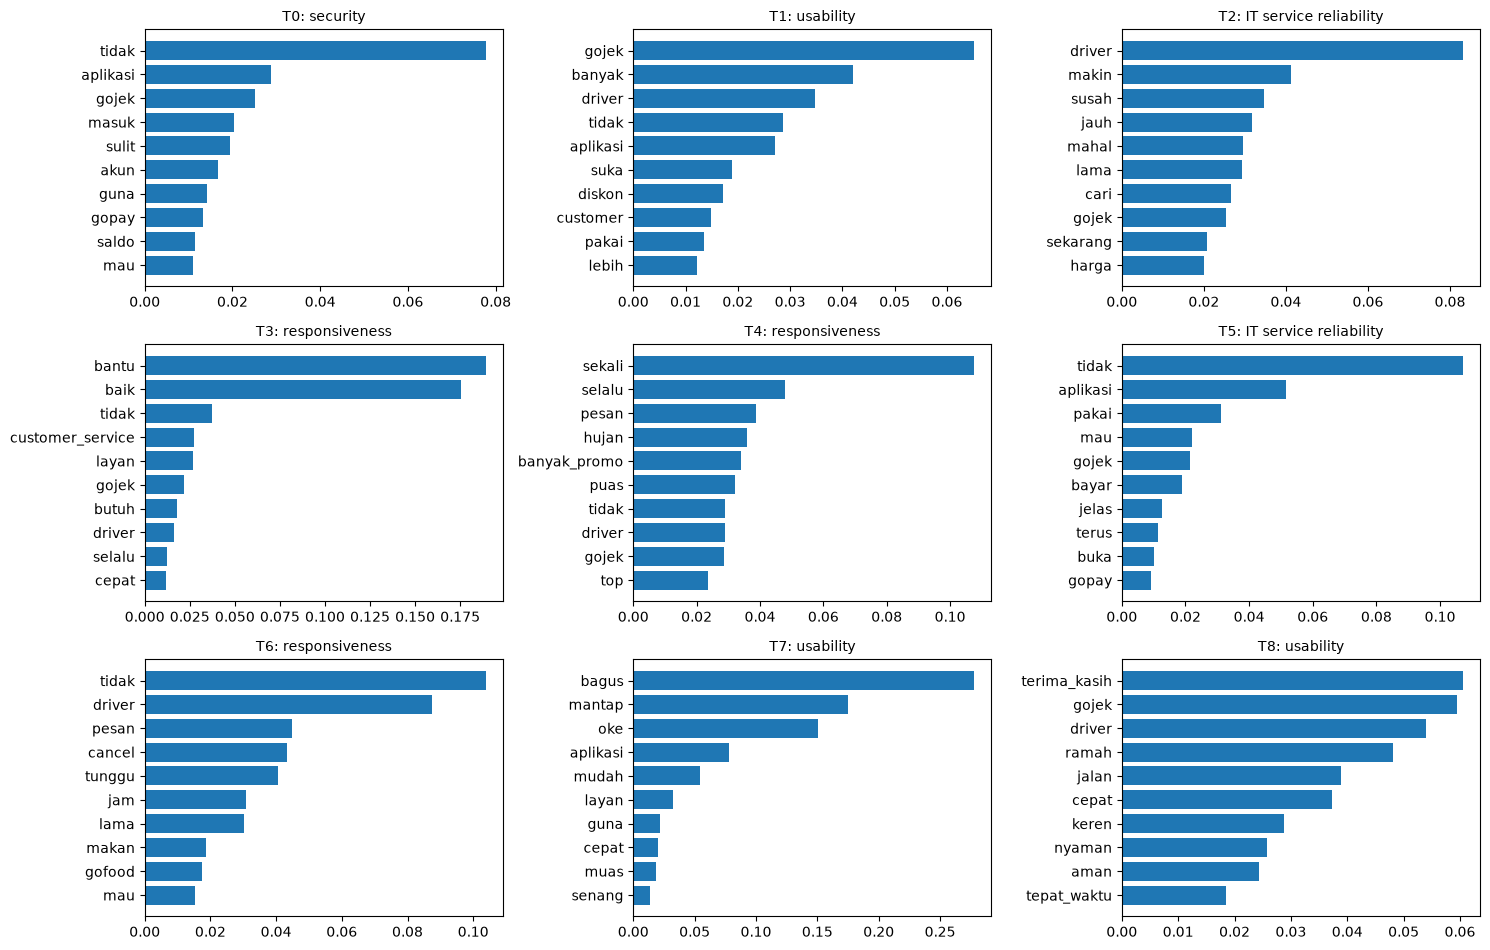

In [ ]:
# 2. Visualisai 10 kata dominan tiap topik
kol = 3; brs = int(np.ceil(K_FINAL / kol))
fig, axes = plt.subplots(brs, kol, figsize=(5 * kol, 3.2 * brs))
for t, ax in zip(range(K_FINAL), np.ravel(axes)):
    kata = lda.show_topic(t, topn=10)[::-1]
    ax.barh([w for w, _ in kata], [p for _, p in kata])
    ax.set_title(f"T{t}: {topic_to_aspect[t]}", fontsize=10)
for ax in np.ravel(axes)[K_FINAL:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(HASIL_DIR / "lda_kata_dominan_per_topik.png", dpi=200)
plt.show()

### PEMETAAN ASPEK & SENTIMEN

label                   positif  negatif  total  persen_negatif
aspek                                                          
security                    448     2242   2690            83.3
IT service reliability     2111     8356  10467            79.8
responsiveness             5517     9568  15085            63.4
usability                 14997     5028  20025            25.1
Tidak teridentifikasi: 138 | total ulasan berlabel: 48405


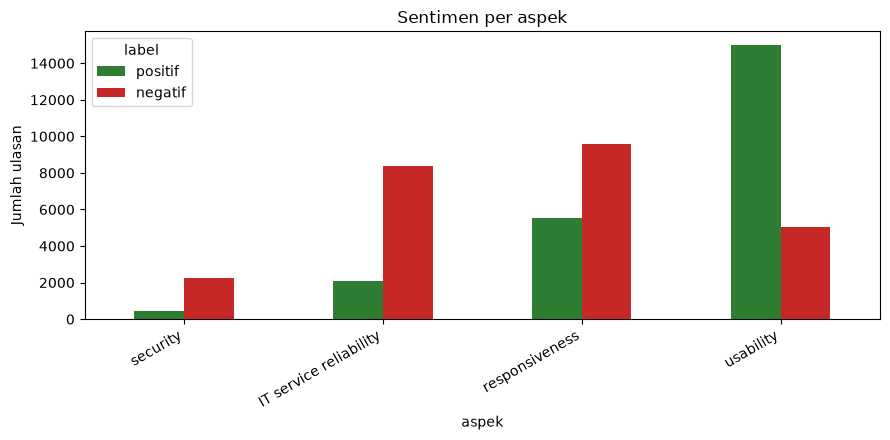

In [137]:
# Gabungkan label aspek (LDA) dengan label sentimen final (InSet + ground truth)
asp = pd.read_csv(HASIL_DIR / "lda_ulasan_beraspek.csv", encoding="utf-8-sig",
                  dtype={"review_id": str}, usecols=["review_id", "aspek", "aspek_prob", "topik_dominan"])

df_gab = df_model.merge(asp, on="review_id", how="left", validate="one_to_one")
assert len(df_gab) == len(df_model)
assert (df_gab["review_id"].values == df_model["review_id"].values).all()   # urutan sama dengan X_all / y_all
assert df_gab["aspek"].notna().all(), "Ada review_id yang tidak ada di hasil LDA"

TAK = "tidak teridentifikasi"
tabel = (pd.crosstab(df_gab["aspek"], df_gab["label"])
           .reindex(columns=["positif", "negatif"], fill_value=0))
tabel["total"] = tabel.sum(axis=1)
tabel["persen_negatif"] = (100 * tabel["negatif"] / tabel["total"]).round(1)

n_tak = int(tabel.loc[TAK, "total"]) if TAK in tabel.index else 0
tabel_aspek = tabel.drop(index=TAK, errors="ignore").sort_values("persen_negatif", ascending=False)

print(tabel_aspek)
print(f"Tidak teridentifikasi: {n_tak} | total ulasan berlabel: {len(df_gab)}")
tabel_aspek.to_csv(HASIL_DIR / "tabel_aspek_sentimen.csv", encoding="utf-8-sig")

ax = tabel_aspek[["positif", "negatif"]].plot(kind="bar", figsize=(9, 4.5), color=["#2e7d32", "#c62828"])
ax.set_ylabel("Jumlah ulasan"); ax.set_title("Sentimen per aspek")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(HASIL_DIR / "grafik_aspek_sentimen.png", dpi=200)
plt.show()

### PEMBOBOTAN FITUR TF-IDF

In [138]:
# 2. TF-IDF sesuai proposal: TF = n_dt / N_d ; IDF = log(N / df(t)) ; TF-IDF = TF x IDF
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
import joblib

MIN_DF = 1   # proposal tidak membatasi; naikkan ke 2 bila ingin membuang kata yang hanya muncul sekali

# Hitung kemunculan tiap kata di tiap ulasan (n_dt)
cv = CountVectorizer(token_pattern=r"\S+", lowercase=False, min_df=MIN_DF)
counts = cv.fit_transform(df_model[KOLOM_SENTIMEN])       # matriks sparse (ulasan x kata)

N_doc   = counts.shape[0]                                  # N  : jumlah dokumen
doc_len = np.asarray(counts.sum(axis=1)).ravel()           # N_d: jumlah kata per ulasan
doc_len[doc_len == 0] = 1                                  # jaga-jaga agar tidak dibagi nol
df_t    = np.asarray((counts > 0).sum(axis=0)).ravel()     # df(t): jumlah ulasan yang memuat kata t

tf    = sparse.diags(1.0 / doc_len) @ counts               # Persamaan 2.4
idf   = np.log(N_doc / df_t)                               # Persamaan 2.5
X_all = (tf @ sparse.diags(idf)).tocsr()                   # Persamaan 2.6

y_all = df_model["label"].map({"negatif": 0, "positif": 1}).to_numpy()
fitur = np.array(cv.get_feature_names_out())
print("Matriks TF-IDF :", X_all.shape, "| jumlah fitur:", len(fitur))
print("Label (0=negatif, 1=positif):", np.bincount(y_all))

# Contoh: 8 kata berbobot tertinggi pada ulasan pertama
i = 0
baris = X_all[i].toarray().ravel()
print("\nUlasan :", df_model[KOLOM_SENTIMEN].iloc[i])
print("Top kata:", [(fitur[j], round(baris[j], 3)) for j in np.argsort(-baris)[:8]])

# Simpan
sparse.save_npz(HASIL_DIR / "tfidf_matrix.npz", X_all)
joblib.dump({"vectorizer": cv, "idf": idf}, HASIL_DIR / "tfidf_model.joblib")

Matriks TF-IDF : (48405, 14731) | jumlah fitur: 14731
Label (0=negatif, 1=positif): [25269 23136]

Ulasan : bantu aktivitas
Top kata: [('aktivitas', np.float64(2.808)), ('bantu', np.float64(1.172)), ('zee', np.float64(0.0)), ('zaman', np.float64(0.0)), ('zalim', np.float64(0.0)), ('zahid', np.float64(0.0)), ('zag', np.float64(0.0)), ('yyaa', np.float64(0.0))]


['c:\\Users\\LENOVO\\OneDrive\\Documents\\Skripsi\\Implementasi_gojek\\implementasiSkripsi\\hasil\\tfidf_model.joblib']

### PEMBAGIAN DATA

In [142]:
# 1. Pembagian data 80:20 + SMOTE pada data training
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

GT_KE_TRAIN = True      # True = data ground truth di training; False = ground truth di testing
TEST_RATIO  = 0.2

idx_all = np.arange(len(df_model))
is_gt   = (df_model["sumber_label"] == "ground_truth").to_numpy()
idx_gt, idx_non = idx_all[is_gt], idx_all[~is_gt]

n_test_total = int(round(TEST_RATIO * len(df_model)))       # jumlah data testing = 20% dari seluruh data
n_ambil_test = n_test_total if GT_KE_TRAIN else n_test_total - len(idx_gt)

# Data di luar sampel validasi dibagi terstratifikasi berdasarkan label
idx_train_non, idx_test_non = train_test_split(
    idx_non, test_size=n_ambil_test, stratify=y_all[idx_non], random_state=SEED)

if GT_KE_TRAIN:
    idx_train = np.concatenate([idx_train_non, idx_gt])
    idx_test  = idx_test_non
else:
    idx_train = idx_train_non
    idx_test  = np.concatenate([idx_test_non, idx_gt])

# Pengecekan
assert len(set(idx_train) & set(idx_test)) == 0, "Ada data di training dan testing sekaligus"
assert len(idx_train) + len(idx_test) == len(df_model)
print(f"Training: {len(idx_train):,} ({len(idx_train)/len(df_model):.1%}) | Testing: {len(idx_test):,} ({len(idx_test)/len(df_model):.1%})")
print("Ground truth di training:", int(is_gt[idx_train].sum()), "| di testing:", int(is_gt[idx_test].sum()))

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]

# Distribusi kelas
dist = pd.DataFrame({"training": np.bincount(y_train), "testing": np.bincount(y_test)},
                    index=["negatif", "positif"])

rasio = dist["training"].min() / dist["training"].max()
print(f"Rasio minoritas/mayoritas pada training: {rasio:.2f}")
# Persentase distribusi positif & negatif =====
dist_persen = (dist / dist.sum() * 100).round(2)      # tiap kolom berjumlah 100%
tabel = dist.join(dist_persen, lsuffix=" (n)", rsuffix=" (%)")
tabel = tabel[["training (n)", "training (%)", "testing (n)", "testing (%)"]]
print("\nDistribusi kelas (jumlah dan persentase):")
print(tabel.to_string())

Training: 38,724 (80.0%) | Testing: 9,681 (20.0%)
Ground truth di training: 382 | di testing: 0
Rasio minoritas/mayoritas pada training: 0.92

Distribusi kelas (jumlah dan persentase):
         training (n)  training (%)  testing (n)  testing (%)
negatif         20211         52.19         5058        52.25
positif         18513         47.81         4623        47.75


### PEMODELAN SVM

In [144]:
# 1. Training SVM kernel linear, C = 1
import time
from sklearn.svm import SVC

svm = SVC(kernel="linear", C=1.0, random_state=SEED, cache_size=2000)

t0 = time.time()
svm.fit(X_train, y_train)
print(f"Training selesai dalam {(time.time() - t0) / 60:.1f} menit | support vector: {svm.n_support_.sum():,}")

joblib.dump(svm, HASIL_DIR / "svm_linear_c1.joblib")

# Kata yang paling berpengaruh bagi tiap kelas (koefisien model linear)
koef = svm.coef_.toarray().ravel() if sparse.issparse(svm.coef_) else svm.coef_.ravel()
print("\nKata pendorong positif :", list(fitur[np.argsort(-koef)[:15]]))
print("Kata pendorong negatif :", list(fitur[np.argsort(koef)[:15]]))

Training selesai dalam 0.7 menit | support vector: 4,997

Kata pendorong positif : ['pakai', 'terus', 'mantap', 'alhamdulillah', 'top', 'manfaat', 'amanah', 'baru', 'harga', 'oke', 'sesuai', 'nama', 'baik', 'sering', 'pas']
Kata pendorong negatif : ['tidak', 'aplikasi', 'lama', 'telat', 'sulit', 'cari', 'jauh', 'parah', 'orang', 'malas', 'terlalu', 'datang', 'buruk', 'salah', 'sistem']


In [150]:
# 5. Klasifikasi data testing
y_pred  = svm.predict(X_test)
skor    = svm.decision_function(X_test)      # jarak ke hyperplane, dipakai untuk ROC/AUC

hasil_uji = df_model.iloc[idx_test][["review_id", "review", KOLOM_SENTIMEN, "source", "sumber_label"]].copy()
hasil_uji["label_aktual"]   = np.where(y_test == 1, "positif", "negatif")
hasil_uji["label_prediksi"] = np.where(y_pred == 1, "positif", "negatif")
hasil_uji["skor_svm"]       = skor
hasil_uji.to_csv(HASIL_DIR / "svm_prediksi_testing.csv", index=False, encoding="utf-8-sig")

print(hasil_uji["label_prediksi"].value_counts())
hasil_uji["aspek"] = df_gab["aspek"].iloc[idx_test].values   # aspek tiap ulasan testing
hasil_uji.head()

label_prediksi
negatif    5124
positif    4557
Name: count, dtype: int64


,review_id,review,review_stem,source,sumber_label,label_aktual,label_prediksi,skor_svm,aspek
31183,gp_9c09d7a4-bd6b-4156-ad93-a4f5cdce2602,susah bet nyari driver taila,susah cari driver taila,Google Play Store,inset,negatif,negatif,-5.347288,IT service reliability
32266,gp_63931b8f-3f0b-4488-9d94-618a205bbc61,semoga aku dapat driver gojek berangkat sama p...,moga driver gojek berangkat pulang rumah amin,Google Play Store,inset,negatif,negatif,-0.518638,usability
31261,as_13920169338,Life for good,life for bagus,App Store,inset,negatif,negatif,-1.000343,usability
42514,gp_d47d318b-c75b-436f-b167-33ea73cc9068,ini apk aneh saya naik gocar disuruh bayar 100...,aplikasi aneh naik gocar suruh bayar ribu tarif,Google Play Store,inset,negatif,negatif,-3.237825,IT service reliability
3812,gp_37e9da6b-692b-4436-a4c7-e38719938eb2,kalau cuaca habis hujan dapat deraeper nya suk...,cuaca habis hujan deraeper suka susah paling j...,Google Play Store,inset,negatif,negatif,-2.809323,IT service reliability


### EVALUASI MODEL SVM

### 1. Evaluasi SVM

TP=4470  TN=4971  FP=87  FN=153
Accuracy=0.9752 | Precision=0.9809 | Recall=0.9669 | F1=0.9739
              precision    recall  f1-score   support

     negatif     0.9701    0.9828    0.9764      5058
     positif     0.9809    0.9669    0.9739      4623

    accuracy                         0.9752      9681
   macro avg     0.9755    0.9749    0.9751      9681
weighted avg     0.9753    0.9752    0.9752      9681



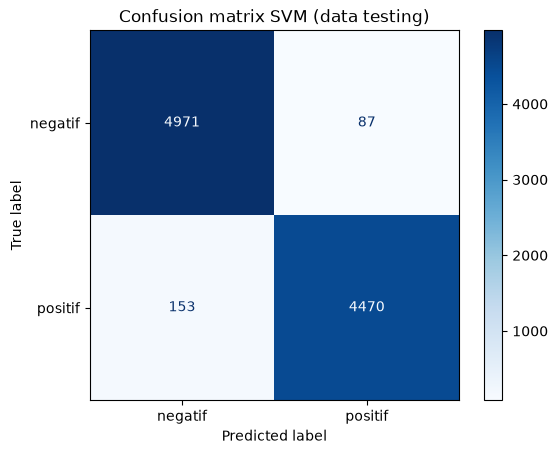

AUC = 0.9973


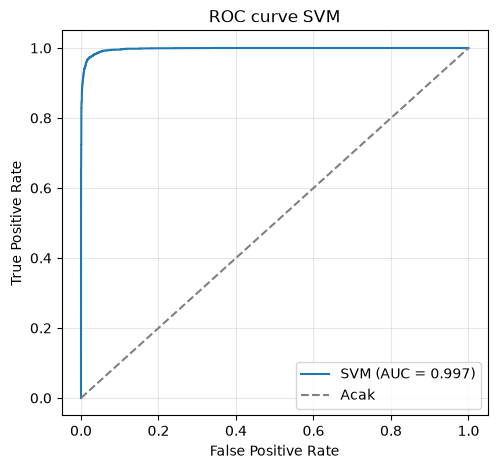

In [ ]:
# 1. Evaluasi SVM: confusion matrix, accuracy, precision, recall, F1, ROC, AUC
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, roc_curve, roc_auc_score,
                             ConfusionMatrixDisplay)

# 6a. Confusion matrix (kelas positif = 1)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec  = recall_score(y_test, y_pred, pos_label=1)
f1   = f1_score(y_test, y_pred, pos_label=1)
print(f"Accuracy={acc:.4f} | Precision={prec:.4f} | Recall={rec:.4f} | F1={f1:.4f}")
print(classification_report(y_test, y_pred, target_names=["negatif", "positif"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["negatif", "positif"]).plot(cmap="Blues")
plt.title("Confusion matrix SVM (data testing)")
plt.savefig(HASIL_DIR / "svm_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# 6b. ROC curve dan AUC
fpr, tpr, _ = roc_curve(y_test, skor)
auc = roc_auc_score(y_test, skor)
print(f"AUC = {auc:.4f}")

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Acak")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve SVM"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(HASIL_DIR / "svm_roc_curve.png", dpi=200, bbox_inches="tight")
plt.show()

# 6c. Simpan ringkasan metrik
pd.DataFrame([{"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc,
               "TP": tp, "TN": tn, "FP": fp, "FN": fn, "n_train": len(idx_train), "n_test": len(idx_test)}]
             ).to_csv(HASIL_DIR / "svm_metrik_evaluasi.csv", index=False)

### 2. Evaluasi SVM peraspek

                 aspek   TN  FP  FN   TP  n_test  accuracy
IT service reliability 1693  29  47  366    2135    0.9644
        responsiveness 1864  25  37 1017    2943    0.9789
              security  429   1  17   63     510    0.9647
             usability  976  31  51 3014    4072    0.9799

                 aspek   kelas  precision  recall     f1  support
IT service reliability negatif     0.9730  0.9832 0.9780     1722
IT service reliability positif     0.9266  0.8862 0.9059      413
        responsiveness negatif     0.9805  0.9868 0.9836     1889
        responsiveness positif     0.9760  0.9649 0.9704     1054
              security negatif     0.9619  0.9977 0.9795      430
              security positif     0.9844  0.7875 0.8750       80
             usability negatif     0.9503  0.9692 0.9597     1007
             usability positif     0.9898  0.9834 0.9866     3065

Akurasi: 97,54%


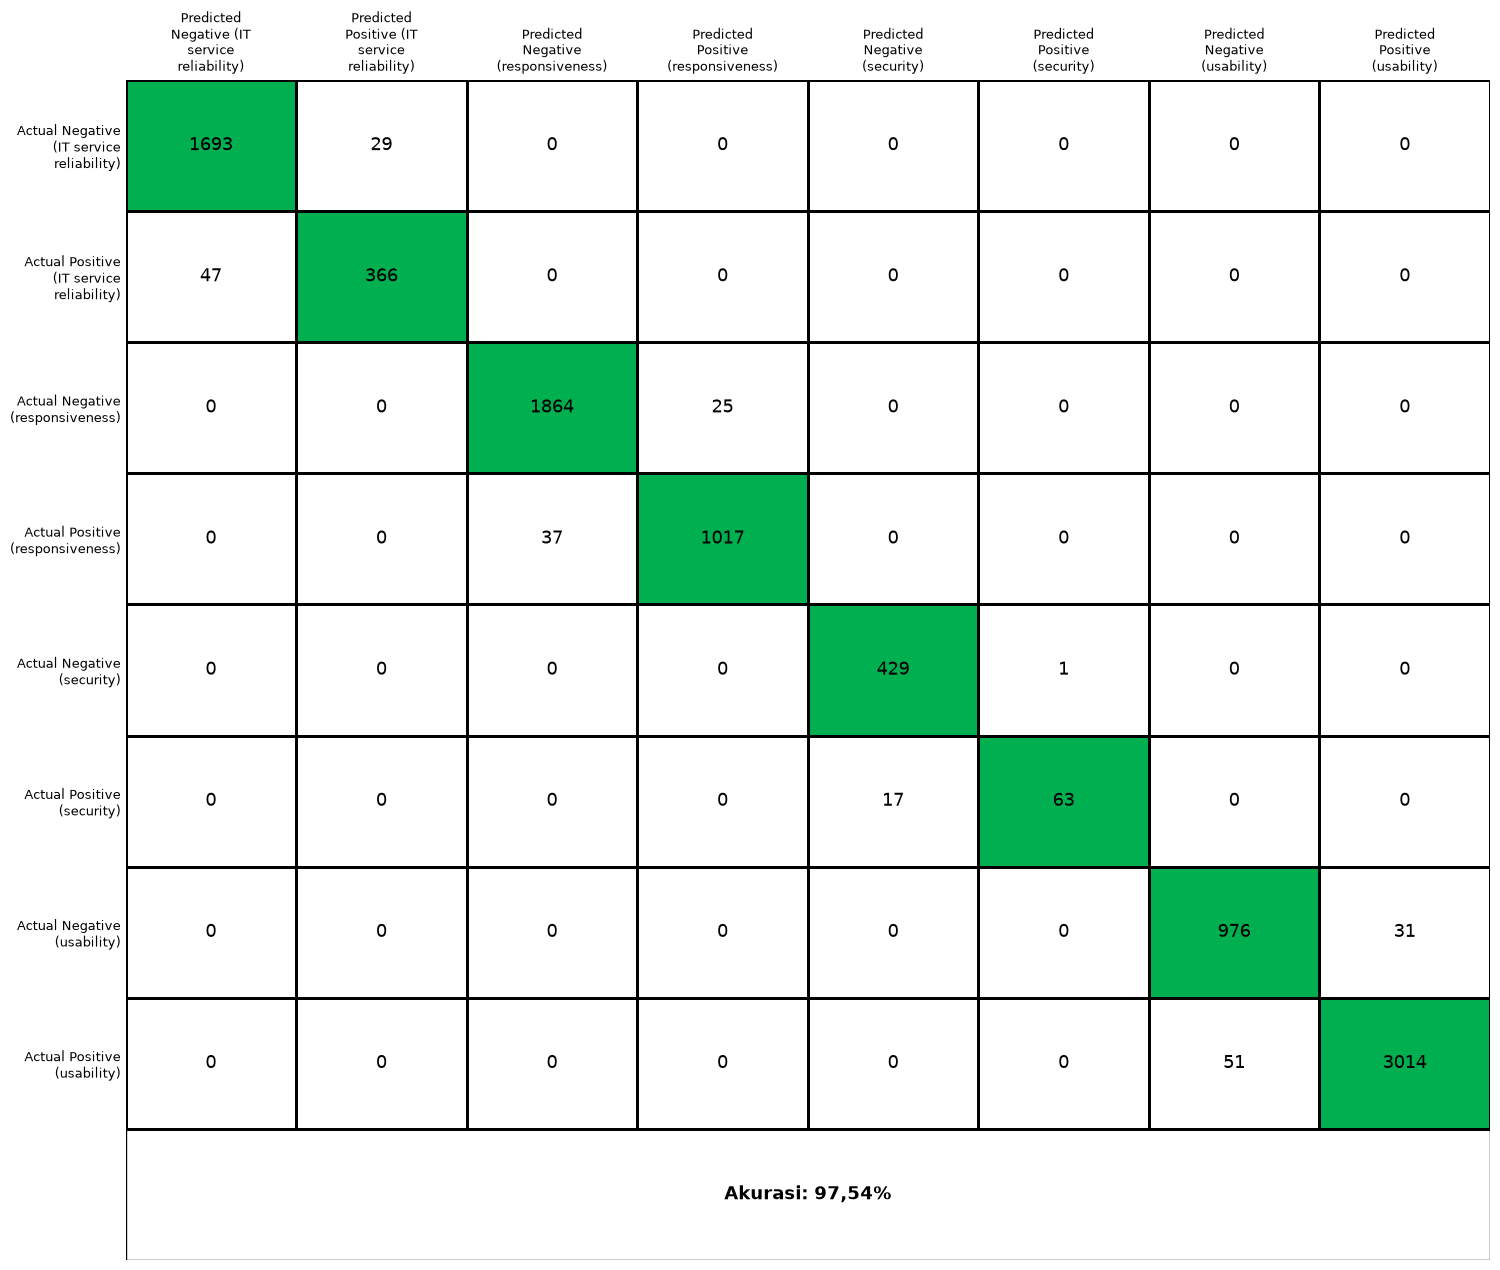

In [153]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

ev = pd.DataFrame({"aspek": df_gab["aspek"].iloc[idx_test].values, "y_true": y_test, "y_pred": y_pred})
ev = ev[ev["aspek"] != "tidak teridentifikasi"].copy()

# ===== (Opsional) tabel metrik per aspek, seperti kodemu sebelumnya =====
cm_rows, met_rows = [], []
for a, g in ev.groupby("aspek"):
    tn, fp, fn, tp = confusion_matrix(g["y_true"], g["y_pred"], labels=[0, 1]).ravel()
    cm_rows.append({"aspek": a, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                    "n_test": len(g), "accuracy": (tp + tn) / len(g)})
    p, r, f, s = precision_recall_fscore_support(g["y_true"], g["y_pred"], labels=[0, 1], zero_division=0)
    for k, nama in enumerate(["negatif", "positif"]):
        met_rows.append({"aspek": a, "kelas": nama, "precision": p[k], "recall": r[k],
                         "f1": f[k], "support": int(s[k])})
tabel_cm  = pd.DataFrame(cm_rows).round(4)
tabel_met = pd.DataFrame(met_rows).round(4)
print(tabel_cm.to_string(index=False)); print(); print(tabel_met.to_string(index=False))
tabel_cm.to_csv(HASIL_DIR / "svm_cm_per_aspek.csv", index=False)
tabel_met.to_csv(HASIL_DIR / "svm_metrik_per_aspek.csv", index=False)

# ===== Confusion matrix gabungan (aspek x sentimen) seperti Tabel 5.2 =====
nama_sent   = {0: "Negative", 1: "Positive"}
aspek_urut  = sorted(ev["aspek"].unique())
kelas       = [(a, s) for a in aspek_urut for s in (0, 1)]      # per aspek: Negative lalu Positive
label_kelas = [f"{nama_sent[s]} ({a})" for a, s in kelas]
pos = {k: i for i, k in enumerate(kelas)}

n = len(kelas)
M = np.zeros((n, n), dtype=int)
for a, yt, yp in zip(ev["aspek"], ev["y_true"], ev["y_pred"]):
    M[pos[(a, int(yt))], pos[(a, int(yp))]] += 1      # aspek berasal dari LDA, sama pada actual & predicted

akurasi = np.trace(M) / M.sum() * 100
cm_df = pd.DataFrame(M, index=[f"Actual {l}" for l in label_kelas],
                        columns=[f"Predicted {l}" for l in label_kelas])
print(f"\nAkurasi: {akurasi:.2f}%".replace(".", ","))
cm_df.to_csv(HASIL_DIR / "svm_cm_gabungan_aspek_sentimen.csv", encoding="utf-8-sig")

# ===== Gambar =====
fig, ax = plt.subplots(figsize=(max(6, 1.7 * n + 1.5), max(6, 1.35 * n + 2)))
ax.pcolormesh(np.arange(n + 1), np.arange(n + 1), np.eye(n),
              cmap=ListedColormap(["white", "#00B050"]), edgecolors="black", linewidth=1, vmin=0, vmax=1)
for i in range(n):
    for j in range(n):
        ax.text(j + 0.5, i + 0.5, f"{M[i, j]}", ha="center", va="center", fontsize=13 if n <= 8 else 9)
ax.add_patch(plt.Rectangle((0, n), n, 1, fill=False, edgecolor="black", linewidth=1))
ax.text(n / 2, n + 0.5, f"Akurasi: {akurasi:.2f}%".replace(".", ","),
        ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_xlim(0, n); ax.set_ylim(n + 1, 0)
ax.set_xticks(np.arange(n) + 0.5)
ax.set_xticklabels([textwrap.fill("Predicted " + l, 16) for l in label_kelas], fontsize=9)
ax.set_yticks(np.arange(n) + 0.5)
ax.set_yticklabels([textwrap.fill("Actual " + l, 18) for l in label_kelas], fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig(HASIL_DIR / "svm_confusion_matrix_gabungan.png", dpi=200)
plt.show()